Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Statistical testing libraries
import scipy.stats as st
from scipy.stats import chi2_contingency
from statsmodels.stats.contingency_tables import Table2x2

# Global alpha
ALPHA = 0.05

def cramers_v(table):
    """Cramér's V effect size for chi-square tests on any r x c table."""
    chi2_val = chi2_contingency(table)[0]
    n = table.sum().sum()
    r, k = table.shape
    return np.sqrt(chi2_val / (n * (min(r, k) - 1)))

def chi_square_report(table, label):
    """Full chi-square test report with effect size."""
    chi2_val, p, dof, expected = chi2_contingency(table)
    v = cramers_v(table)
    print(f"--- Chi-Square Test: {label} ---")
    print(f"Chi² = {chi2_val:.4f}, df = {dof}, p = {p:.4f}")
    print(f"Cramér's V = {v:.4f}")
    if p < ALPHA:
        print("→ Significant association (reject H0)")
    else:
        print("→ No significant association (fail to reject H0)")
    # Warn if any expected cell < 5 (chi-square assumption violation)
    if (expected < 5).any():
        print("⚠ Warning: some expected counts < 5 — consider Fisher's exact test.")
    print()
    return chi2_val, p, v


In [3]:
df = pd.read_excel('df_final.xlsx')  # Load your dataset here
df.head()

,Student_ID,Academic Year,APPLIED MECHANICS,COMPUTER SKILLS,CONSTRUCTION MATERIALS TECHNOLOGY,ENGINEERING CHEMISTRY,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS 1,ENGINEERING PHYSICS,PROFESSIONAL AND TECHNICAL COMMUNICATION,...,Language Name,Ethnic Group Name,Previous Activity Desc,Matric Type,Age_At_Enrolment,Bursary Type,Funded,Residence_Status,At_Risk_Status,Secondary_School_Quintile
0,ebad61ae15967effac440603214e2e829bb29399e52236...,2022,80,76,67,77,67,62,50,58,...,ISIZULU,AFRICAN,UNEMPLOYED,B,19,NSFAS,Yes,Yes,No,3
1,f521b30f9daaa32d07004bfe337461cbe32083db1a4c4f...,2022,68,42,62,72,65,66,55,63,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,Yes,2
2,a39ac7e2e46a3c504ea680c833542b44509590f9566861...,2022,50,59,63,69,73,51,50,62,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,No,5
3,32d8a74e94211a616b9c701f62ebf8ef4a90162ab430a6...,2022,56,62,62,75,55,50,53,57,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,Yes,1
4,d5aa2443cbcb70dfffa1a66fcbcf4bca0953a2d8d55e39...,2022,64,66,71,78,53,69,56,59,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,No,3


Demographics Distribution

In [4]:
# Display-label helper for EDA plots.
# Gender/Funded/Residence_Status get numerically encoded (0/1) for modelling
# later in the notebook. This helper always returns readable category names
# for plotting -- "Male"/"Female", "No"/"Yes" -- whether that encoding cell
# has already run or not, so moving cells around no longer breaks the labels.
GENDER_LABELS = {0: "Male", 1: "Female"}
YESNO_LABELS = {0: "No", 1: "Yes"}

def to_readable(series, mapping):
    s = series.copy()
    if pd.api.types.is_numeric_dtype(s):
        s = s.map(mapping).fillna(s)
    return s


Available columns:
['Student_ID', 'Academic Year', 'APPLIED MECHANICS', 'COMPUTER SKILLS', 'CONSTRUCTION MATERIALS TECHNOLOGY', 'ENGINEERING CHEMISTRY', 'ENGINEERING DRAWING 1', 'ENGINEERING MATHEMATICS 1', 'ENGINEERING PHYSICS', 'PROFESSIONAL AND TECHNICAL COMMUNICATION', 'SURVEYING', 'THEORY OF STRUCTURES', 'Gender', 'Language Name', 'Ethnic Group Name', 'Previous Activity Desc', 'Matric Type', 'Age_At_Enrolment', 'Bursary Type', 'Funded', 'Residence_Status', 'At_Risk_Status', 'Secondary_School_Quintile']
MODULE COLUMN CHECK

Available module columns:
['APPLIED MECHANICS', 'COMPUTER SKILLS', 'CONSTRUCTION MATERIALS TECHNOLOGY', 'ENGINEERING CHEMISTRY', 'ENGINEERING DRAWING 1', 'ENGINEERING MATHEMATICS 1', 'ENGINEERING PHYSICS', 'PROFESSIONAL AND TECHNICAL COMMUNICATION', 'SURVEYING', 'THEORY OF STRUCTURES']

Missing module columns:
[]

Academic Years:
['2022', '2023', '2024', '2025']
AT-RISK DISTRIBUTION BY ACADEMIC YEAR
At_Risk_Status   No  Yes  Total
Academic Year                  

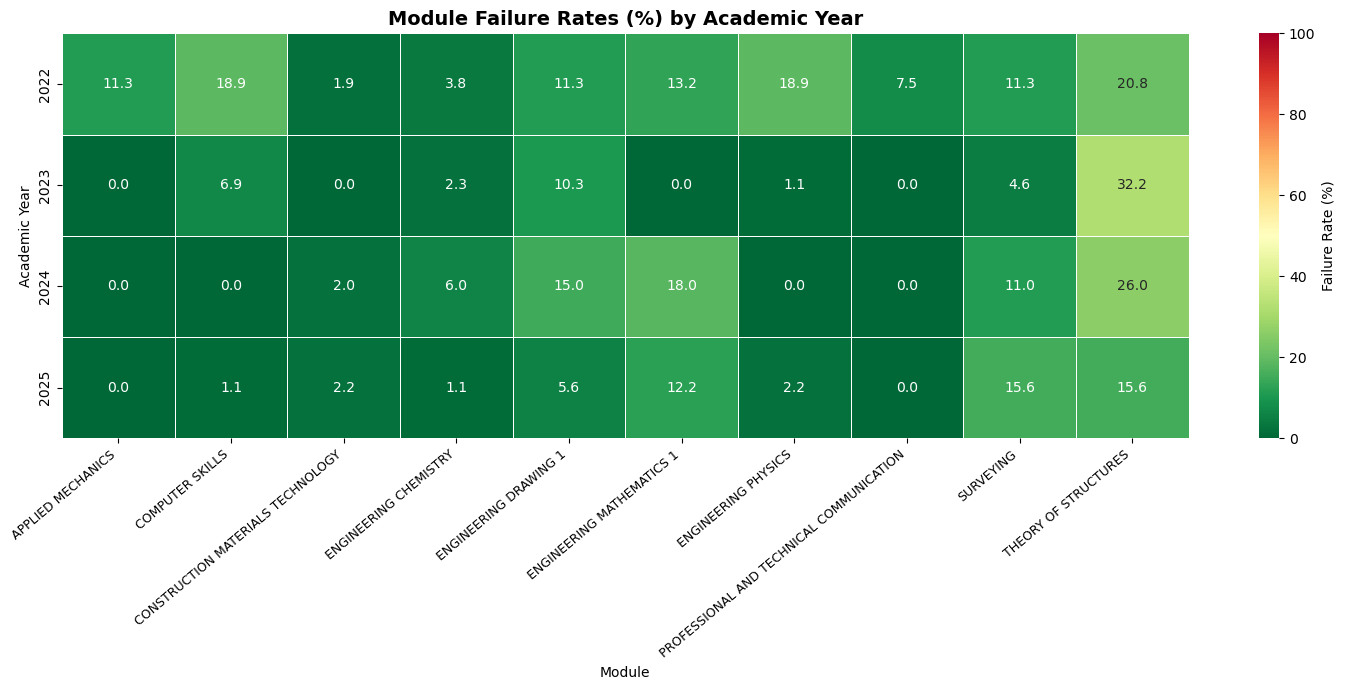

In [5]:
# YEAR-BY-YEAR ANALYSIS

# 1. CLEAN COLUMN NAMES

# Remove leading/trailing spaces from column names
df.columns = df.columns.astype(str).str.strip()

print("Available columns:")
print(df.columns.tolist())

# 2. DEFINE MODULES

MODULES = [
    'APPLIED MECHANICS',
    'COMPUTER SKILLS',
    'CONSTRUCTION MATERIALS TECHNOLOGY',
    'ENGINEERING CHEMISTRY',
    'ENGINEERING DRAWING 1',
    'ENGINEERING MATHEMATICS 1',
    'ENGINEERING PHYSICS',
    'PROFESSIONAL AND TECHNICAL COMMUNICATION',
    'SURVEYING',
    'THEORY OF STRUCTURES'
]

# 3. CHECK WHICH MODULES EXIST

available_modules = [m for m in MODULES if m in df.columns]
missing_modules = [m for m in MODULES if m not in df.columns]

print("MODULE COLUMN CHECK")

print("\nAvailable module columns:")
print(available_modules)

print("\nMissing module columns:")
print(missing_modules)


# Stop if none of the modules are found
if len(available_modules) == 0:
    raise ValueError(
        "None of the module columns were found in df. "
        "Please check the column names printed above."
    )

# 4. CLEAN ACADEMIC YEAR

df["Academic Year"] = df["Academic Year"].astype(str).str.strip()

years = sorted(
    df["Academic Year"].dropna().unique()
)

print("\nAcademic Years:")
print(years)

# 5. AT-RISK DISTRIBUTION BY YEAR
print("AT-RISK DISTRIBUTION BY ACADEMIC YEAR")

atrisk_by_year = pd.crosstab(
    df["Academic Year"],
    df["At_Risk_Status"],
    margins=True,
    margins_name="Total"
)

print(atrisk_by_year)

# 6. AT-RISK PERCENTAGE BY YEAR

print("AT-RISK PERCENTAGE BY ACADEMIC YEAR")

atrisk_percentage = pd.crosstab(
    df["Academic Year"],
    df["At_Risk_Status"],
    normalize="index"
) * 100

print(atrisk_percentage.round(1))

# 7. MODULE FAILURE RATE BY YEAR

print("MODULE FAILURE RATES BY ACADEMIC YEAR (%)")

yearly_fail = {}

for yr in years:

    ydf = df[df["Academic Year"] == yr]

    rates = {}

    for module in available_modules:

        # Convert marks to numeric
        marks = pd.to_numeric(
            ydf[module],
            errors="coerce"
        )

        # Remove missing marks
        valid = marks.dropna()

        # Failure = mark below 50
        if len(valid) > 0:

            failure_rate = (
                (valid < 50).sum() / len(valid)
            ) * 100

            rates[module] = round(failure_rate, 1)

        else:
            rates[module] = None

    yearly_fail[yr] = rates


# Convert to DataFrame
yearly_fail_df = pd.DataFrame(yearly_fail).T

yearly_fail_df.index.name = "Academic Year"

print(yearly_fail_df.to_string())

# 8. OVERALL MODULE FAILURE RATE

print("OVERALL MODULE FAILURE RATES (%)")

overall_failure = {}

for module in available_modules:

    marks = pd.to_numeric(
        df[module],
        errors="coerce"
    )

    valid = marks.dropna()

    if len(valid) > 0:

        failure_rate = (
            (valid < 50).sum() / len(valid)
        ) * 100

        overall_failure[module] = round(
            failure_rate,
            1
        )

    else:
        overall_failure[module] = None


overall_failure_df = pd.DataFrame.from_dict(
    overall_failure,
    orient="index",
    columns=["Failure Rate (%)"]
)

overall_failure_df = overall_failure_df.sort_values(
    "Failure Rate (%)",
    ascending=False
)

print(overall_failure_df)

# 9. HEATMAP

plt.figure(figsize=(15, 7))

sns.heatmap(
    yearly_fail_df.astype(float),
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Failure Rate (%)"
    }
)

plt.title(
    "Module Failure Rates (%) by Academic Year",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Module")
plt.ylabel("Academic Year")

plt.xticks(
    rotation=40,
    ha="right",
    fontsize=9
)

plt.tight_layout()
plt.show()

In [6]:
results = []
for module in available_modules:
    marks = pd.to_numeric(df[module], errors='coerce').dropna()
    n = len(marks)
    k = (marks < 50).sum()
    p0 = 0.20
    if n > 0:
        z = (k/n - p0) / np.sqrt(p0 * (1 - p0) / n)
        p = 2 * (1 - st.norm.cdf(abs(z)))
        results.append((module, n, k, k/n*100, z, p))

fail_df = pd.DataFrame(results, columns=['Module','N','Fail','Rate%','z','p'])
fail_df['Significant'] = fail_df['p'] < ALPHA
print(fail_df.sort_values('p'))

                                     Module    N  Fail      Rate%         z  \
2         CONSTRUCTION MATERIALS TECHNOLOGY  330     5   1.515152 -8.394849   
7  PROFESSIONAL AND TECHNICAL COMMUNICATION  330     4   1.212121 -8.532469   
0                         APPLIED MECHANICS  330     6   1.818182 -8.257228   
3                     ENGINEERING CHEMISTRY  330    11   3.333333 -7.569126   
6                       ENGINEERING PHYSICS  330    13   3.939394 -7.293885   
1                           COMPUTER SKILLS  330    17   5.151515 -6.743403   
4                     ENGINEERING DRAWING 1  330    35  10.606061 -4.266235   
8                                 SURVEYING  330    35  10.606061 -4.266235   
5                 ENGINEERING MATHEMATICS 1  330    36  10.909091 -4.128614   
9                      THEORY OF STRUCTURES  330    79  23.939394  1.789066   

              p  Significant  
2  0.000000e+00         True  
7  0.000000e+00         True  
0  2.220446e-16         True  
3  3.7

In [7]:
# count students with subject mark < 50 for each subject and year, and create a summary table.
# List of module columns
MODULES = [
    'APPLIED MECHANICS',
    'COMPUTER SKILLS',
    'CONSTRUCTION MATERIALS TECHNOLOGY',
    'ENGINEERING CHEMISTRY',
    'ENGINEERING DRAWING 1',
    'ENGINEERING MATHEMATICS 1',
    'ENGINEERING PHYSICS',
    'PROFESSIONAL AND TECHNICAL COMMUNICATION',
    'SURVEYING',
    'THEORY OF STRUCTURES'
]

# Create an empty list to store results
results = []

# Loop through each module
for module in MODULES:
    
    # Convert marks to numeric
    marks = pd.to_numeric(df[module], errors='coerce')
    
    # Count marks below 50 for each academic year
    failed = (
        df.assign(Failed=marks < 50)
          .groupby('Academic Year')['Failed']
          .sum()
    )
    
    # Store results
    for year, count in failed.items():
        results.append({
            'Subject': module,
            'Academic Year': year,
            'Students_Failed': int(count)
        })

# Convert to DataFrame
summary_long = pd.DataFrame(results)

# Create summary table
summary_table = (
    summary_long
    .pivot(
        index='Subject',
        columns='Academic Year',
        values='Students_Failed'
    )
    .fillna(0)
    .astype(int)
)

print(summary_table)



Academic Year                             2022  2023  2024  2025
Subject                                                         
APPLIED MECHANICS                            6     0     0     0
COMPUTER SKILLS                             10     6     0     1
CONSTRUCTION MATERIALS TECHNOLOGY            1     0     2     2
ENGINEERING CHEMISTRY                        2     2     6     1
ENGINEERING DRAWING 1                        6     9    15     5
ENGINEERING MATHEMATICS 1                    7     0    18    11
ENGINEERING PHYSICS                         10     1     0     2
PROFESSIONAL AND TECHNICAL COMMUNICATION     4     0     0     0
SURVEYING                                    6     4    11    14
THEORY OF STRUCTURES                        11    28    26    14


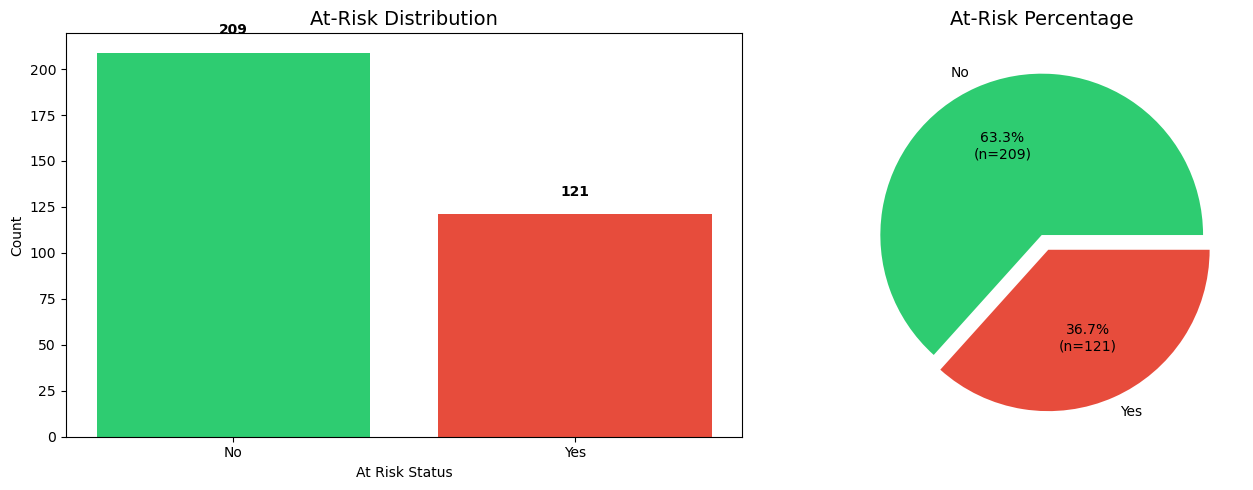


Target variable distribution:
Not At-Risk: 209 (63.3%)
At-Risk: 121 (36.7%)


In [8]:
# 5.1 Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
risk_counts = df['At_Risk_Status'].value_counts()
axes[0].bar(risk_counts.index, risk_counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('At-Risk Distribution', fontsize=14)
axes[0].set_xlabel('At Risk Status')
axes[0].set_ylabel('Count')
for i, v in enumerate(risk_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Pie chart -- show both count and percentage on each slice
def _pct_and_count(pct, values=risk_counts.values):
    count = int(round(pct / 100 * sum(values)))
    return f"{pct:.1f}%\n(n={count})"

axes[1].pie(risk_counts.values, labels=risk_counts.index, autopct=_pct_and_count,
            colors=['#2ecc71', '#e74c3c'], explode=(0, 0.1))
axes[1].set_title('At-Risk Percentage', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nTarget variable distribution:")
print(f"Not At-Risk: {risk_counts.get('No', 0)} ({risk_counts.get('No', 0)/len(df)*100:.1f}%)")
print(f"At-Risk: {risk_counts.get('Yes', 0)} ({risk_counts.get('Yes', 0)/len(df)*100:.1f}%)")


In [9]:
from scipy.stats import binomtest

n_total = len(df)
n_at_risk = (df['At_Risk_Status'] == 'Yes').sum()

result = binomtest(n_at_risk, n_total, p=0.5, alternative='two-sided')
print("--- Binomial Test: At-Risk vs Not (50/50 baseline) ---")
print(f"n = {n_total}, At-Risk = {n_at_risk} ({n_at_risk/n_total:.1%})")
print(f"p-value = {result.pvalue:.4e}")
print("→" , "Significant" if result.pvalue < ALPHA else "Not significant")

--- Binomial Test: At-Risk vs Not (50/50 baseline) ---
n = 330, At-Risk = 121 (36.7%)
p-value = 1.4616e-06
→ Significant


Gender

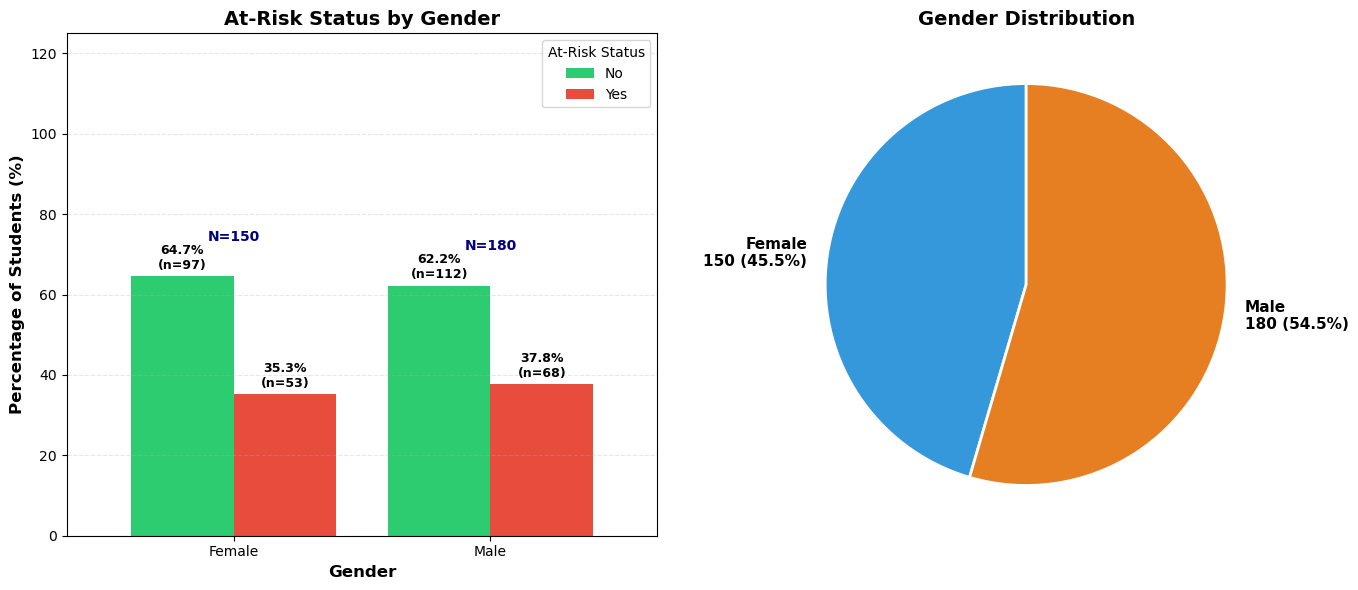

In [10]:
col = df["Gender"].replace({"F": "Female", "M": "Male"})

# Percentage table
gender = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in gender.columns:
        gender[status] = 0
gender = gender[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(gender.index)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
gender.plot(kind="bar", ax=ax, width=0.8, color=["#2ecc71", "#e74c3c"])

for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(gender.index, gender[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

for i, cat in enumerate(gender.index):
    ax.text(i, gender.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Gender", fontsize=14, fontweight="bold")
ax.set_xlabel("Gender", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")

ax2 = axes[1]
pie_data = counts.dropna()
pie_labels = [
    f"{cat}\n{n} ({n / pie_data.sum() * 100:.1f}%)"
    for cat, n in pie_data.items()
]

ax2.pie(
    pie_data.values,
    labels=pie_labels,
    colors=["#3498db", "#e67e22"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11, "fontweight": "bold"},
)
ax2.set_title("Gender Distribution", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

In [11]:
gender_table = pd.crosstab(df['Gender'], df['At_Risk_Status'])
chi_square_report(gender_table, "Gender vs At-Risk Status")

--- Chi-Square Test: Gender vs At-Risk Status ---
Chi² = 0.1184, df = 1, p = 0.7308
Cramér's V = 0.0189
→ No significant association (fail to reject H0)



(np.float64(0.11842105263157895),
 np.float64(0.730753334722013),
 np.float64(0.01894338076060206))

In [12]:
for g in df['Gender'].unique():
    sub = df[df['Gender'] == g]
    n = len(sub)
    k = (sub['At_Risk_Status'] == 'Yes').sum()
    lo, hi = st.beta.ppf([0.025, 0.975], k + 0.5, n - k + 0.5)
    print(f"{g}: n={n}, at-risk={k} ({k/n:.1%}), 95% CI [{lo:.1%}, {hi:.1%}]")

M: n=180, at-risk=68 (37.8%), 95% CI [30.9%, 45.0%]
F: n=150, at-risk=53 (35.3%), 95% CI [28.0%, 43.2%]



Numerical Variables Summary:


,APPLIED MECHANICS,COMPUTER SKILLS,CONSTRUCTION MATERIALS TECHNOLOGY,ENGINEERING CHEMISTRY,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS 1,ENGINEERING PHYSICS,PROFESSIONAL AND TECHNICAL COMMUNICATION,SURVEYING,THEORY OF STRUCTURES,Secondary_School_Quintile
count,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000
mean,65.721212,70.287879,66.175758,67.103030,61.275758,61.227273,58.127273,74.890909,62.563636,56.206061,3.142424
std,12.301970,12.449979,9.891172,9.428421,12.053314,12.481227,8.043320,9.448641,13.288838,15.022373,1.495999
min,20.000000,2.000000,0.000000,30.000000,10.000000,18.000000,18.000000,19.000000,12.000000,0.000000,1.000000
25%,56.000000,65.000000,60.000000,62.000000,54.000000,53.000000,53.000000,70.000000,54.000000,50.000000,2.000000
50%,65.000000,71.000000,66.000000,68.000000,61.000000,62.000000,58.000000,76.000000,63.000000,56.000000,3.000000
75%,73.000000,78.000000,72.000000,72.000000,69.000000,69.000000,63.000000,81.000000,72.000000,65.000000,5.000000
max,99.000000,96.000000,92.000000,94.000000,89.000000,97.000000,82.000000,95.000000,94.000000,94.000000,5.000000


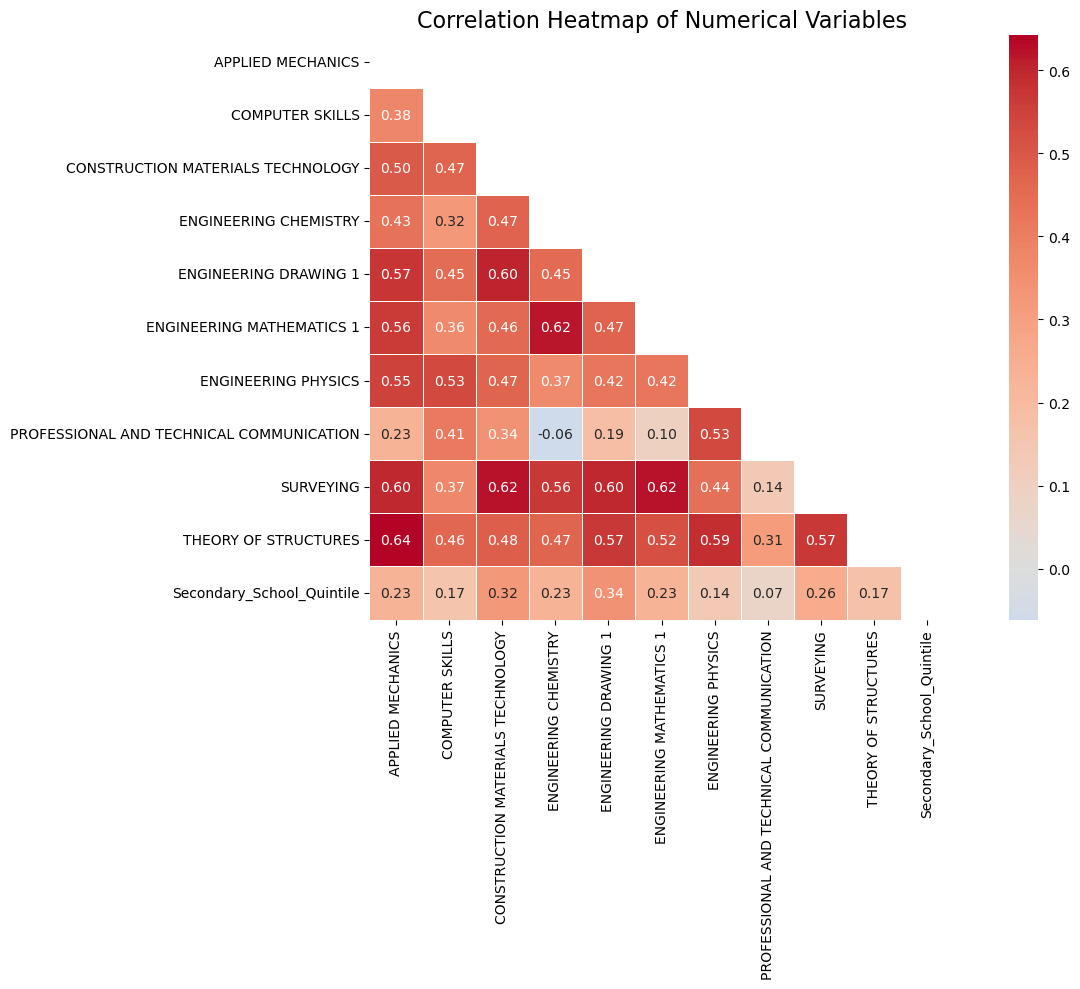

In [13]:
# 5.2 Numerical Summary Statistics
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Remove target and any columns we don't want in the summary/heatmap
for drop_col in ['At_Risk_Status', 'Age_At_Enrolment']:
    if drop_col in numeric_cols:
        numeric_cols.remove(drop_col)

print("\nNumerical Variables Summary:")
display(df[numeric_cols].describe())

# Correlation Heatmap
if len(numeric_cols) > 1:
    plt.figure(figsize=(14, 10))
    corr_matrix = df[numeric_cols].corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0,
                annot=True, fmt='.2f', square=True, linewidths=0.5)
    plt.title('Correlation Heatmap of Numerical Variables', fontsize=16)
    plt.tight_layout()
    plt.show()

In [14]:
from itertools import combinations

corr_results = []
for a, b in combinations(numeric_cols, 2):
    r, p = st.pearsonr(df[a], df[b])
    rho, p_s = st.spearmanr(df[a], df[b])
    corr_results.append((a, b, r, p, rho, p_s))

corr_df = pd.DataFrame(corr_results, columns=['Var1','Var2','Pearson_r','p_pearson',
                                               'Spearman_rho','p_spearman'])
corr_df['sig_pearson'] = corr_df['p_pearson'] < ALPHA
print(corr_df[corr_df['sig_pearson']].sort_values('Pearson_r', ascending=False))

                                        Var1  \
8                          APPLIED MECHANICS   
24         CONSTRUCTION MATERIALS TECHNOLOGY   
42                 ENGINEERING MATHEMATICS 1   
28                     ENGINEERING CHEMISTRY   
20         CONSTRUCTION MATERIALS TECHNOLOGY   
7                          APPLIED MECHANICS   
37                     ENGINEERING DRAWING 1   
47                       ENGINEERING PHYSICS   
3                          APPLIED MECHANICS   
52                                 SURVEYING   
38                     ENGINEERING DRAWING 1   
31                     ENGINEERING CHEMISTRY   
4                          APPLIED MECHANICS   
5                          APPLIED MECHANICS   
14                           COMPUTER SKILLS   
45                       ENGINEERING PHYSICS   
43                 ENGINEERING MATHEMATICS 1   
1                          APPLIED MECHANICS   
25         CONSTRUCTION MATERIALS TECHNOLOGY   
34                     ENGINEERING DRAWI

Language Name

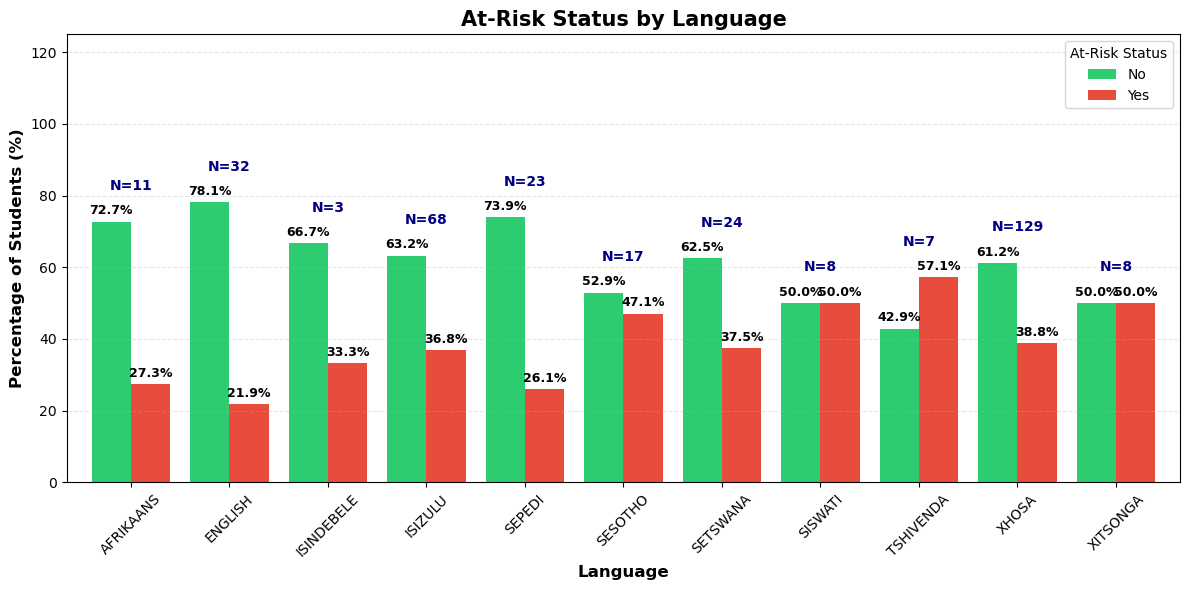

In [15]:
col = df["Language Name"]

# Percentage table
language = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)

for status in ["No", "Yes"]:
    if status not in language.columns:
        language[status] = 0

language = language[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(language.index)

# Plot
ax = language.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
    color=["#2ecc71", "#e74c3c"]
)

# Labels: percentage ONLY
for container, status in zip(
    ax.containers,
    ["No", "Yes"]
):
    labels = [
        f"{pct:.1f}%"
        for pct in language[status]
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=9,
        fontweight="bold"
    )

# Total sample size per category
for i, cat in enumerate(language.index):
    ax.text(
        i,
        language.loc[cat].max() + 8,
        f"N={int(counts.loc[cat])}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="navy"
    )

# Formatting
ax.set_title(
    "At-Risk Status by Language",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Language",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Percentage of Students (%)",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylim(0, 125)

ax.tick_params(
    axis="x",
    rotation=45
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.legend(
    title="At-Risk Status"
)

plt.tight_layout()
plt.show()

In [16]:
lang_table = pd.crosstab(df['Language Name'], df['At_Risk_Status'])
chi_square_report(lang_table, "Language vs At-Risk Status")

--- Chi-Square Test: Language vs At-Risk Status ---
Chi² = 8.0860, df = 10, p = 0.6204
Cramér's V = 0.1565
→ No significant association (fail to reject H0)
⚠ Warning: some expected counts < 5 — consider Fisher's exact test.



(np.float64(8.086036978199736),
 np.float64(0.6204331945242821),
 np.float64(0.15653479599814546))

In [17]:
# For a 2-column table (No/Yes), Fisher's exact works if you collapse to 2x2.
# For larger tables (like Language, which has several categories), use a
# Monte Carlo permutation test instead, since some expected cell counts < 5.
if (chi2_contingency(lang_table)[3] < 5).any():
    rng = np.random.default_rng(42)
    observed = chi2_contingency(lang_table)[0]
    n_perm = 10_000
    perm_stats = []
    row_sums = lang_table.sum(axis=1).values
    col_sums = lang_table.sum(axis=0).values
    for _ in range(n_perm):
        flat = np.repeat(np.arange(len(row_sums)), row_sums)
        rng.shuffle(flat)
        perm = pd.crosstab(flat, np.repeat(np.arange(len(col_sums)), col_sums))
        perm = perm.reindex(index=range(len(row_sums)), columns=range(len(col_sums))).fillna(0)
        try:
            perm_stats.append(chi2_contingency(perm)[0])
        except Exception:
            pass
    p_mc = np.mean(np.array(perm_stats) >= observed)
    print(f"Monte Carlo p-value = {p_mc:.4f}")


Monte Carlo p-value = 0.6328


Ethnic Group Name

Text(0.5, 1.0, 'Ethnic Group Distribution')

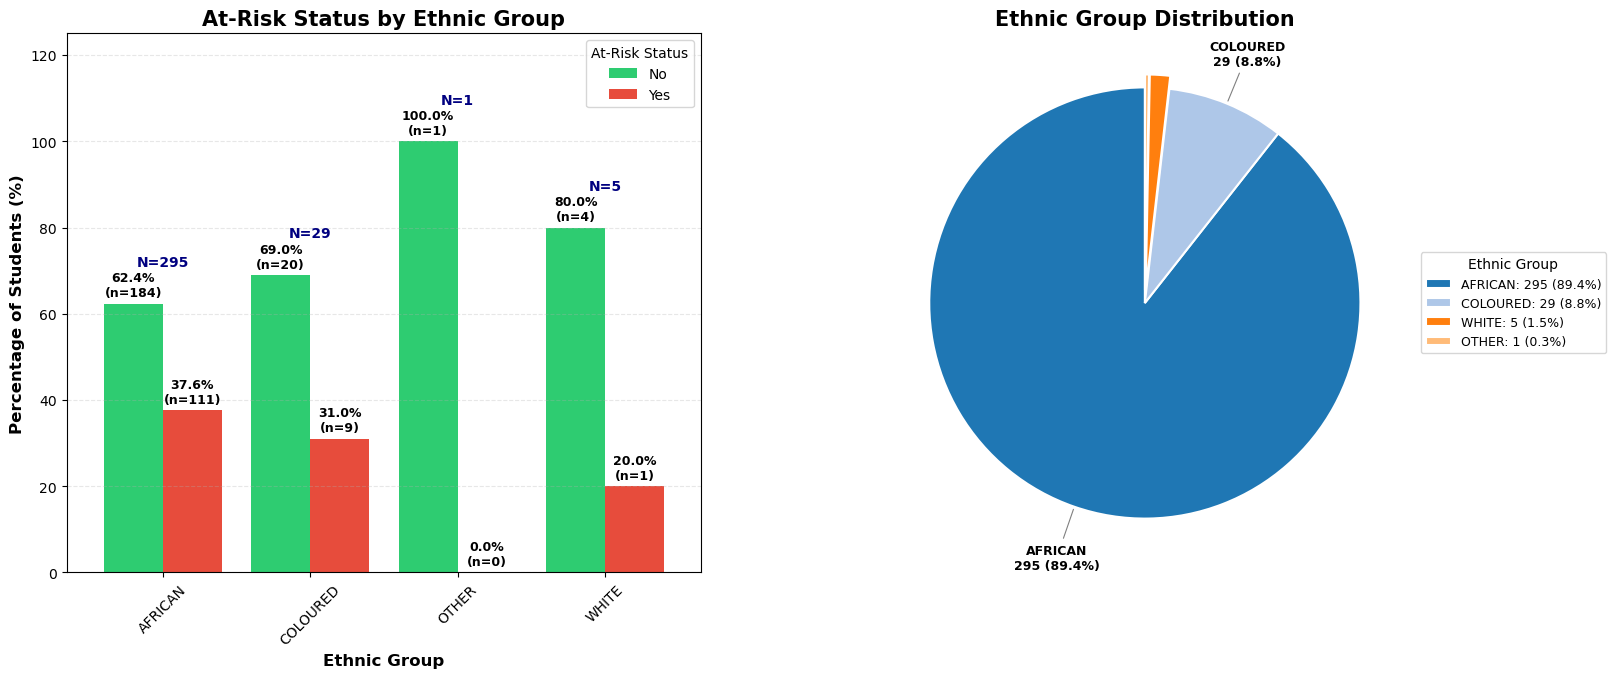

In [18]:
col = df["Ethnic Group Name"]

# Percentage table
ethnic = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in ethnic.columns:
        ethnic[status] = 0
ethnic = ethnic[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(ethnic.index)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ax = axes[0]
ethnic.plot(kind="bar", ax=ax, width=0.8, color=["#2ecc71", "#e74c3c"])

for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(ethnic.index, ethnic[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

for i, cat in enumerate(ethnic.index):
    ax.text(i, ethnic.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Ethnic Group", fontsize=15, fontweight="bold")
ax.set_xlabel("Ethnic Group", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")

# ---------- Right: pie chart ----------
ax2 = axes[1]
pie_data = counts.dropna().sort_values(ascending=False)
total = pie_data.sum()

# Explode tiny slices so their wedges are visible at all
explode = [0.06 if n / total < 0.05 else 0 for n in pie_data.values]

wedges, _ = ax2.pie(
    pie_data.values,
    colors=plt.cm.tab20.colors,
    startangle=90,
    explode=explode,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)

# Only annotate slices >= 5% — keeps leader lines from colliding
for w, (cat, n) in zip(wedges, pie_data.items()):
    pct = n / total * 100
    if pct < 5:
        continue
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    ax2.annotate(
        f"{cat}\n{n} ({pct:.1f}%)",
        xy=(x * 1.0, y * 1.0),
        xytext=(x * 1.25, y * 1.25),
        ha="center", va="center",
        fontsize=9, fontweight="bold",
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.8),
    )

# Legend carries the full breakdown, including the tiny slices
ax2.legend(
    wedges,
    [f"{cat}: {n} ({n/total*100:.1f}%)" for cat, n in pie_data.items()],
    title="Ethnic Group",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    fontsize=9,
)

ax2.set_title("Ethnic Group Distribution", fontsize=15, fontweight="bold")

In [19]:
eth_table = pd.crosstab(df['Ethnic Group Name'], df['At_Risk_Status'])
chi_square_report(eth_table, "Ethnic Group vs At-Risk Status")

# Sensitivity: collapse small groups
df['Ethnic_collapsed'] = df['Ethnic Group Name'].replace(
    {'OTHER': 'Other', 'WHITE': 'Other', 'COLOURED': 'Other'}
)
eth_small = pd.crosstab(df['Ethnic_collapsed'], df['At_Risk_Status'])
chi_square_report(eth_small, "Ethnic (collapsed) vs At-Risk Status")

--- Chi-Square Test: Ethnic Group vs At-Risk Status ---
Chi² = 1.6904, df = 3, p = 0.6391
Cramér's V = 0.0716
→ No significant association (fail to reject H0)
⚠ Warning: some expected counts < 5 — consider Fisher's exact test.

--- Chi-Square Test: Ethnic (collapsed) vs At-Risk Status ---
Chi² = 0.7493, df = 1, p = 0.3867
Cramér's V = 0.0477
→ No significant association (fail to reject H0)



(np.float64(0.7493309545049063),
 np.float64(0.38668813722759954),
 np.float64(0.04765186105637512))

In [20]:
# Remove missing values for the two variables
ethnic_df = df[["Ethnic Group Name", "At_Risk_Status"]].dropna()

# Frequency table
ct = pd.crosstab(
    ethnic_df["Ethnic Group Name"],
    ethnic_df["At_Risk_Status"]
)

# Ensure both statuses exist
for status in ["No", "Yes"]:
    if status not in ct.columns:
        ct[status] = 0

# Total per ethnic group
ct["N"] = ct["No"] + ct["Yes"]

# Percentage of entire sample
ct["% of Sample"] = ct["N"] / ct["N"].sum() * 100

# Within-group percentages
ct["No %"] = ct["No"] / ct["N"] * 100
ct["Yes %"] = ct["Yes"] / ct["N"] * 100

# Build final research table
research_table = pd.DataFrame({
    "N": ct["N"].astype(int),
    "% of Sample": ct["% of Sample"].round(1),
    "Not At-Risk n (%)": [
        f"{n} ({p:.1f}%)"
        for n, p in zip(ct["No"], ct["No %"])
    ],
    "At-Risk n (%)": [
        f"{n} ({p:.1f}%)"
        for n, p in zip(ct["Yes"], ct["Yes %"])
    ],
    "At-Risk Rate (%)": ct["Yes %"].round(1)
})

# Overall totals
total_n = ct["N"].sum()
total_no = ct["No"].sum()
total_yes = ct["Yes"].sum()

research_table.loc["Total"] = [
    total_n,
    100.0,
    f"{total_no} ({total_no / total_n * 100:.1f}%)",
    f"{total_yes} ({total_yes / total_n * 100:.1f}%)",
    round(total_yes / total_n * 100, 1)
]

print(research_table)

                     N  % of Sample Not At-Risk n (%) At-Risk n (%)  \
Ethnic Group Name                                                     
AFRICAN            295         89.4       184 (62.4%)   111 (37.6%)   
COLOURED            29          8.8        20 (69.0%)     9 (31.0%)   
OTHER                1          0.3        1 (100.0%)      0 (0.0%)   
WHITE                5          1.5         4 (80.0%)     1 (20.0%)   
Total              330        100.0       209 (63.3%)   121 (36.7%)   

                   At-Risk Rate (%)  
Ethnic Group Name                    
AFRICAN                        37.6  
COLOURED                       31.0  
OTHER                           0.0  
WHITE                          20.0  
Total                          36.7  


Previous Activity Desc

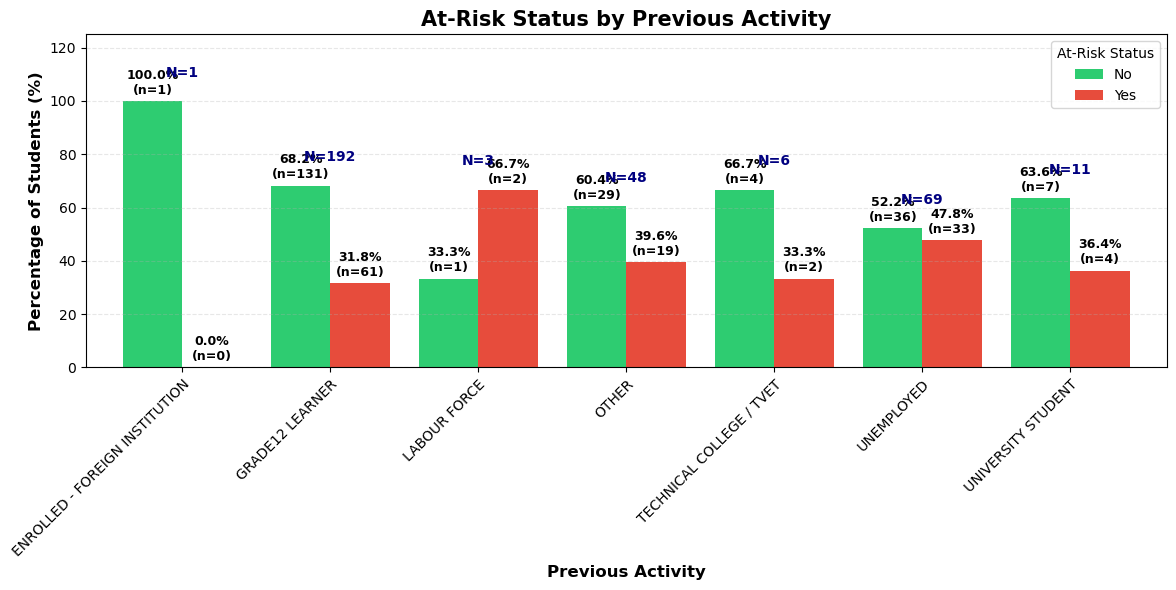

In [21]:
col = df["Previous Activity Desc"]

# Percentage table
previous_activity = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in previous_activity.columns:
        previous_activity[status] = 0
previous_activity = previous_activity[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(previous_activity.index)

ax = previous_activity.plot(kind="bar", figsize=(12, 6), width=0.8,
                            color=["#2ecc71", "#e74c3c"])

# Labels combine percentage AND the underlying count for that slice
for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(previous_activity.index, previous_activity[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

# Total sample size per category above each pair of bars
for i, cat in enumerate(previous_activity.index):
    ax.text(i, previous_activity.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Previous Activity", fontsize=15, fontweight="bold")
ax.set_xlabel("Previous Activity", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)

# --- tick label alignment fix ---
ax.tick_params(axis="x", rotation=45)
for lbl in ax.get_xticklabels():
    lbl.set_horizontalalignment("right")
    lbl.set_rotation_mode("anchor")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")
plt.tight_layout()
plt.show()

In [22]:
prev_table = pd.crosstab(df['Previous Activity Desc'], df['At_Risk_Status'])
chi_square_report(prev_table, "Previous Activity vs At-Risk Status")

--- Chi-Square Test: Previous Activity vs At-Risk Status ---
Chi² = 7.6286, df = 6, p = 0.2666
Cramér's V = 0.1520
→ No significant association (fail to reject H0)
⚠ Warning: some expected counts < 5 — consider Fisher's exact test.



(np.float64(7.628594426688355),
 np.float64(0.26659524780678096),
 np.float64(0.15204260195138247))

Matric Type

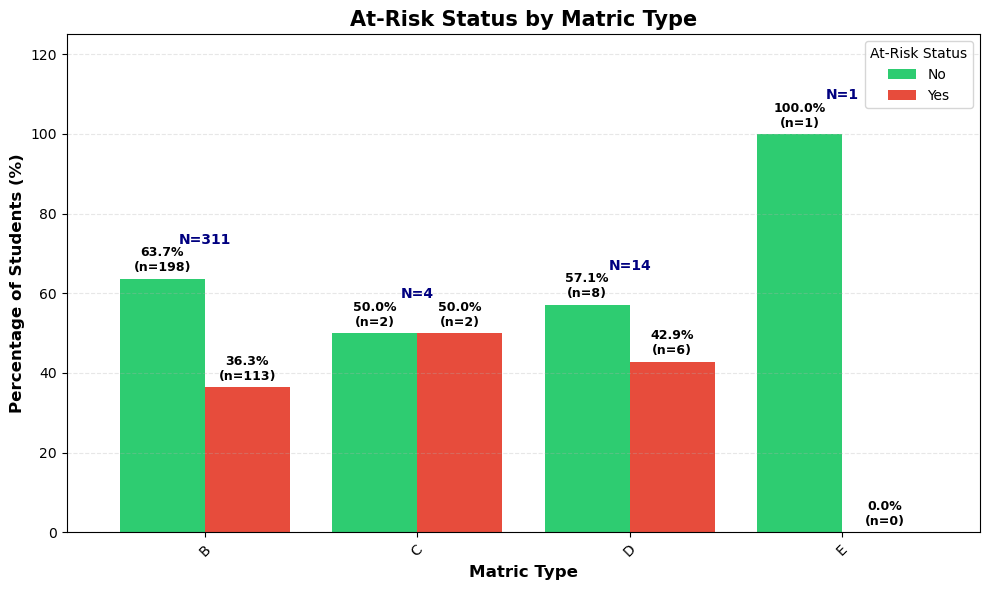

In [23]:
col = df["Matric Type"]

# Percentage table
matric = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in matric.columns:
        matric[status] = 0
matric = matric[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(matric.index)

ax = matric.plot(kind="bar", figsize=(10, 6), width=0.8, color=["#2ecc71", "#e74c3c"])

# Labels combine percentage AND the underlying count for that slice
for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(matric.index, matric[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

# Total sample size per category above each pair of bars
for i, cat in enumerate(matric.index):
    ax.text(i, matric.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Matric Type", fontsize=15, fontweight="bold")
ax.set_xlabel("Matric Type", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")
plt.tight_layout()
plt.show()


In [24]:
matric_table = pd.crosstab(df['Matric Type'], df['At_Risk_Status'])
chi_square_report(matric_table, "Matric Type vs At-Risk Status")

--- Chi-Square Test: Matric Type vs At-Risk Status ---
Chi² = 1.1310, df = 3, p = 0.7696
Cramér's V = 0.0585
→ No significant association (fail to reject H0)
⚠ Warning: some expected counts < 5 — consider Fisher's exact test.



(np.float64(1.1309844327275365),
 np.float64(0.769600069808956),
 np.float64(0.05854251065439376))

Bursary Type

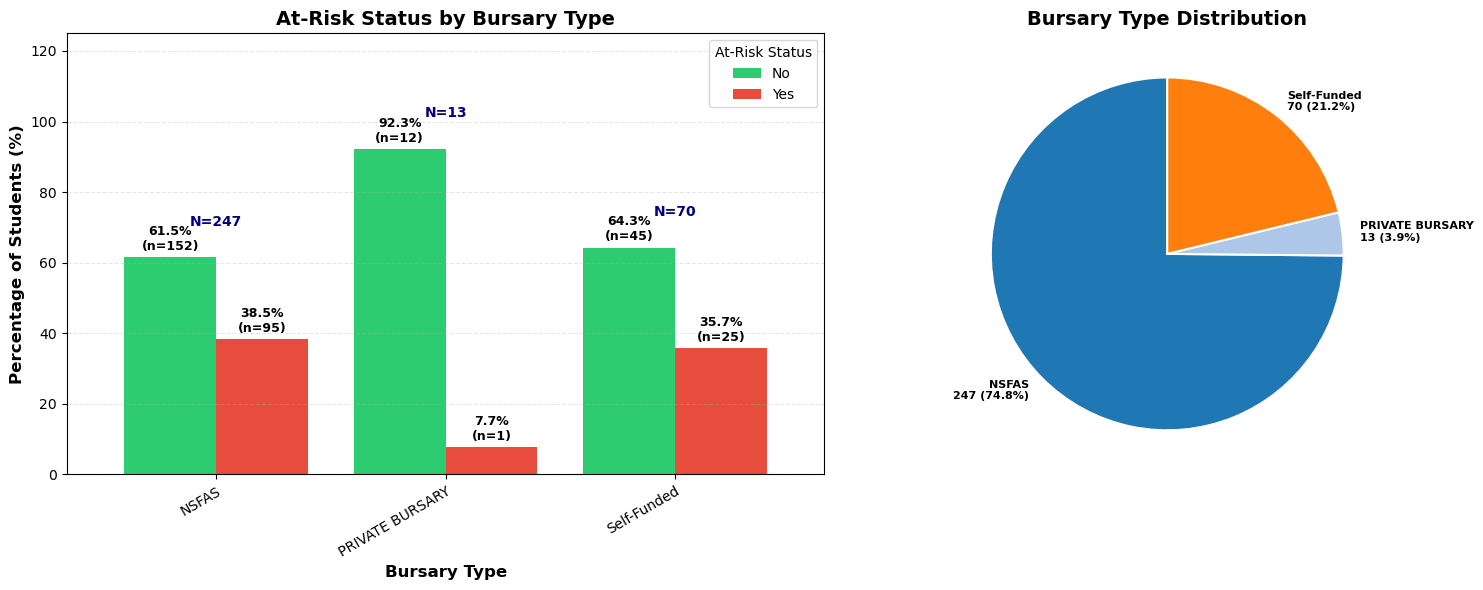

In [25]:
col = df["Bursary Type"]

# Percentage table
bursary = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in bursary.columns:
        bursary[status] = 0
bursary = bursary[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(bursary.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
bursary.plot(kind="bar", ax=ax, width=0.8, color=["#2ecc71", "#e74c3c"])

for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(bursary.index, bursary[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

for i, cat in enumerate(bursary.index):
    ax.text(i, bursary.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Bursary Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Bursary Type", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)

# tick label alignment fix for rotated labels
ax.tick_params(axis="x", rotation=30)
for lbl in ax.get_xticklabels():
    lbl.set_horizontalalignment("right")
    lbl.set_rotation_mode("anchor")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")

ax2 = axes[1]
pie_data = counts.dropna()
total = pie_data.sum()

pie_labels = [
    f"{cat}\n{n} ({n / total * 100:.1f}%)"
    for cat, n in pie_data.items()
]

wedges, _ = ax2.pie(
    pie_data.values,
    labels=pie_labels,
    colors=plt.cm.tab20.colors,
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    labeldistance=1.1,        # push labels outward
    textprops={"fontsize": 8, "fontweight": "bold"},
)
ax2.set_title("Bursary Type Distribution", fontsize=14, fontweight="bold")

# No separate legend needed — every slice is labelled
plt.tight_layout()
plt.show()

In [26]:
bursary_table = pd.crosstab(df['Bursary Type'], df['At_Risk_Status'])
chi_square_report(bursary_table, "Bursary Type vs At-Risk Status")

--- Chi-Square Test: Bursary Type vs At-Risk Status ---
Chi² = 5.0697, df = 2, p = 0.0793
Cramér's V = 0.1239
→ No significant association (fail to reject H0)
⚠ Warning: some expected counts < 5 — consider Fisher's exact test.



(np.float64(5.069667174930333),
 np.float64(0.07927491050591315),
 np.float64(0.12394606812166004))

Funded

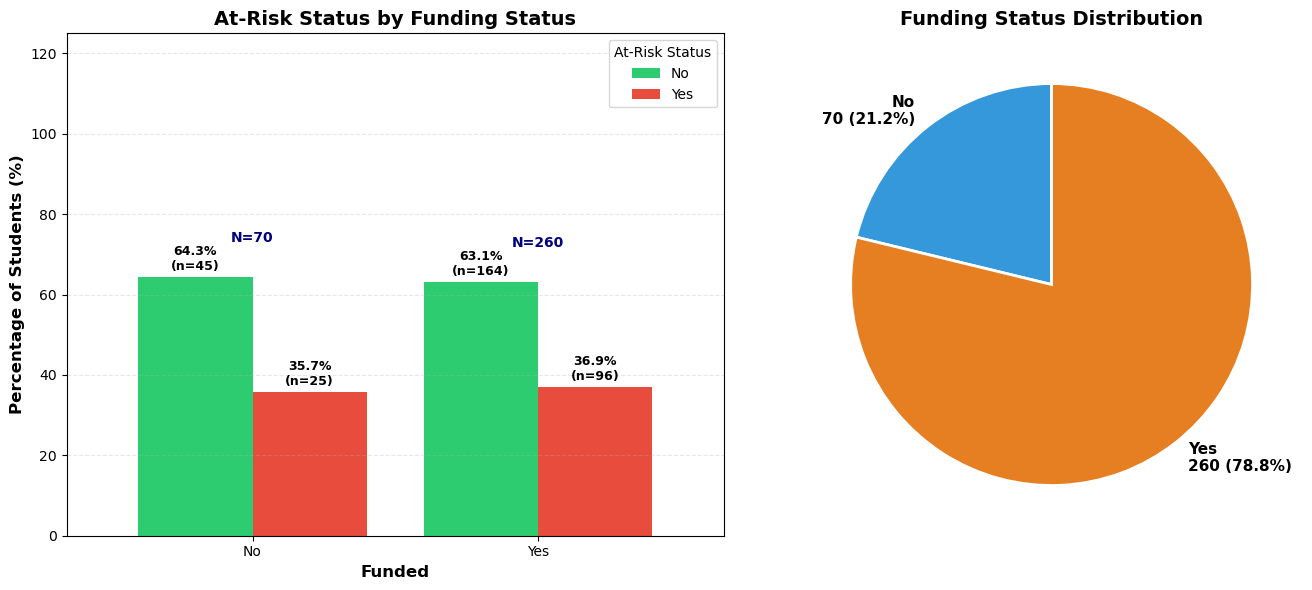

In [27]:
col = to_readable(df["Funded"], YESNO_LABELS)

# Percentage table
funded = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in funded.columns:
        funded[status] = 0
funded = funded[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(funded.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
funded.plot(kind="bar", ax=ax, width=0.8, color=["#2ecc71", "#e74c3c"])

for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(funded.index, funded[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

for i, cat in enumerate(funded.index):
    ax.text(i, funded.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Funding Status", fontsize=14, fontweight="bold")
ax.set_xlabel("Funded", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")

ax2 = axes[1]
pie_data = counts.dropna()
total = pie_data.sum()

pie_labels = [
    f"{cat}\n{n} ({n / total * 100:.1f}%)"
    for cat, n in pie_data.items()
]

ax2.pie(
    pie_data.values,
    labels=pie_labels,
    colors=["#3498db", "#e67e22"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11, "fontweight": "bold"},
)
ax2.set_title("Funding Status Distribution", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

In [28]:
funded_table = pd.crosstab(df['Funded'], df['At_Risk_Status'])
chi_square_report(funded_table, "Funded vs At-Risk Status")

# Additionally report odds ratio via 2x2
t = Table2x2(funded_table.values)
print(f"Odds Ratio = {t.oddsratio:.4f}, 95% CI = {t.oddsratio_confint()}")

--- Chi-Square Test: Funded vs At-Risk Status ---
Chi² = 0.0022, df = 1, p = 0.9629
Cramér's V = 0.0026
→ No significant association (fail to reject H0)

Odds Ratio = 1.0537, 95% CI = (np.float64(0.6079286357212195), np.float64(1.826195126344273))


Residence Status

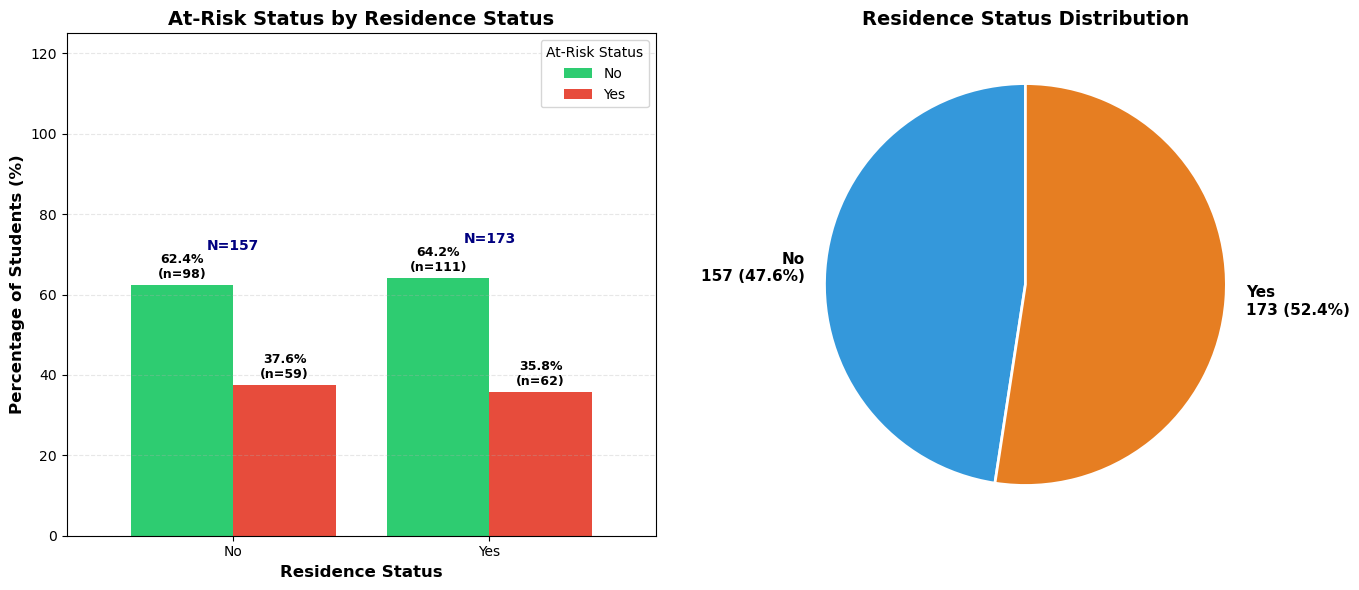

In [29]:
col = to_readable(df["Residence_Status"], YESNO_LABELS)

# Percentage table
residence = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in residence.columns:
        residence[status] = 0
residence = residence[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(residence.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
residence.plot(kind="bar", ax=ax, width=0.8, color=["#2ecc71", "#e74c3c"])

for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(residence.index, residence[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight="bold")

for i, cat in enumerate(residence.index):
    ax.text(i, residence.loc[cat].max() + 8, f"N={int(counts.loc[cat])}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="navy")

ax.set_title("At-Risk Status by Residence Status", fontsize=14, fontweight="bold")
ax.set_xlabel("Residence Status", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 125)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status")

ax2 = axes[1]
pie_data = counts.dropna()
total = pie_data.sum()

pie_labels = [
    f"{cat}\n{n} ({n / total * 100:.1f}%)"
    for cat, n in pie_data.items()
]

ax2.pie(
    pie_data.values,
    labels=pie_labels,
    colors=["#3498db", "#e67e22"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11, "fontweight": "bold"},
)
ax2.set_title("Residence Status Distribution", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

In [30]:
res_table = pd.crosstab(df['Residence_Status'], df['At_Risk_Status'])
chi_square_report(res_table, "Residence Status vs At-Risk Status")

--- Chi-Square Test: Residence Status vs At-Risk Status ---
Chi² = 0.0456, df = 1, p = 0.8309
Cramér's V = 0.0118
→ No significant association (fail to reject H0)



(np.float64(0.04557618411848251),
 np.float64(0.8309480686939953),
 np.float64(0.011752006162519079))

Secondary School Quintile

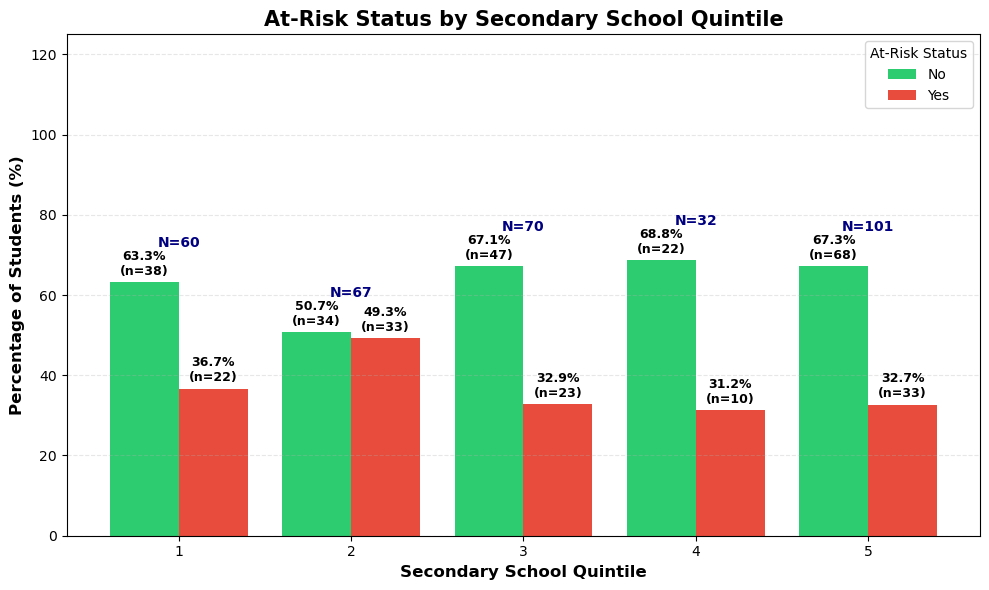

In [31]:
# Convert to string
df['Secondary_School_Quintile'] = (
    df['Secondary_School_Quintile']
    .astype(str)
    .str.strip()
)

# Replace missing/invalid values
df['Secondary_School_Quintile'] = (
    df['Secondary_School_Quintile']
    .replace(['nan', 'NaN', 'None', ''], 'Others')
)

# Keep only expected categories
df.loc[
    ~df['Secondary_School_Quintile'].isin(['1', '2', '3', '4', '5', 'Others']),
    'Secondary_School_Quintile'
] = 'Others'

# Percentage table
quintile = (
    pd.crosstab(df['Secondary_School_Quintile'], df['At_Risk_Status'], normalize='index') * 100
)
for status in ['No', 'Yes']:
    if status not in quintile.columns:
        quintile[status] = 0
quintile = quintile[['No', 'Yes']]

order = ['1', '2', '3', '4', '5', 'Others']
quintile = quintile.reindex([x for x in order if x in quintile.index])

# Actual counts per quintile
quintile_counts = df['Secondary_School_Quintile'].value_counts().reindex(quintile.index)

ax = quintile.plot(kind='bar', figsize=(10, 6), width=0.8, color=['#2ecc71', '#e74c3c'])

for container, status in zip(ax.containers, ['No', 'Yes']):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*quintile_counts.loc[cat]))})"
        for cat, pct in zip(quintile.index, quintile[status])
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight='bold')

for i, cat in enumerate(quintile.index):
    ax.text(i, quintile.loc[cat].max() + 8, f"N={int(quintile_counts.loc[cat])}",
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='navy')

ax.set_title('At-Risk Status by Secondary School Quintile', fontsize=15, fontweight='bold')
ax.set_xlabel('Secondary School Quintile', fontsize=12, fontweight='bold')
ax.set_ylabel('Percentage of Students (%)', fontsize=12, fontweight='bold')
ax.set_ylim(0, 125)
ax.set_xticklabels(quintile.index, rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(title='At-Risk Status')
plt.tight_layout()
plt.show()


In [32]:
quint = df[df['Secondary_School_Quintile'].isin(['1','2','3','4','5'])].copy()
quint['Quintile_num'] = quint['Secondary_School_Quintile'].astype(int)
quint['At_Risk_num'] = (quint['At_Risk_Status'] == 'Yes').astype(int)

quint_table = pd.crosstab(quint['Quintile_num'], quint['At_Risk_num'])
chi_square_report(quint_table, "Quintile vs At-Risk Status")

# Cochran-Armitage trend test (tests for monotonic trend in risk across quintiles)
from scipy.stats import chi2_contingency
def cochran_armitage(table):
    """table: rows=groups in order, cols=[neg, pos]"""
    n = table.sum().sum()
    row_tot = table.sum(axis=1).values
    col_tot = table.sum(axis=0).values
    scores = np.arange(len(row_tot))
    R = (table.iloc[:, 1] * scores).sum()           # weighted positives
    E = (row_tot * scores).sum() * col_tot[1] / n   # expected
    Var = (col_tot[0] * col_tot[1] / (n * (n - 1))) * \
          ((row_tot * scores**2).sum() - ((row_tot * scores).sum()**2) / n)
    z = (R - E) / np.sqrt(Var)
    p = 2 * (1 - st.norm.cdf(abs(z)))
    return z, p

z, p = cochran_armitage(quint_table)
print(f"Cochran-Armitage trend: z = {z:.4f}, p = {p:.4f}")
print("→", "Significant trend" if p < ALPHA else "No significant trend")

--- Chi-Square Test: Quintile vs At-Risk Status ---
Chi² = 6.1064, df = 4, p = 0.1913
Cramér's V = 0.1360
→ No significant association (fail to reject H0)

Cochran-Armitage trend: z = -1.3923, p = 0.1638
→ No significant trend


Year by year analysis

At-Risk Status Distribution

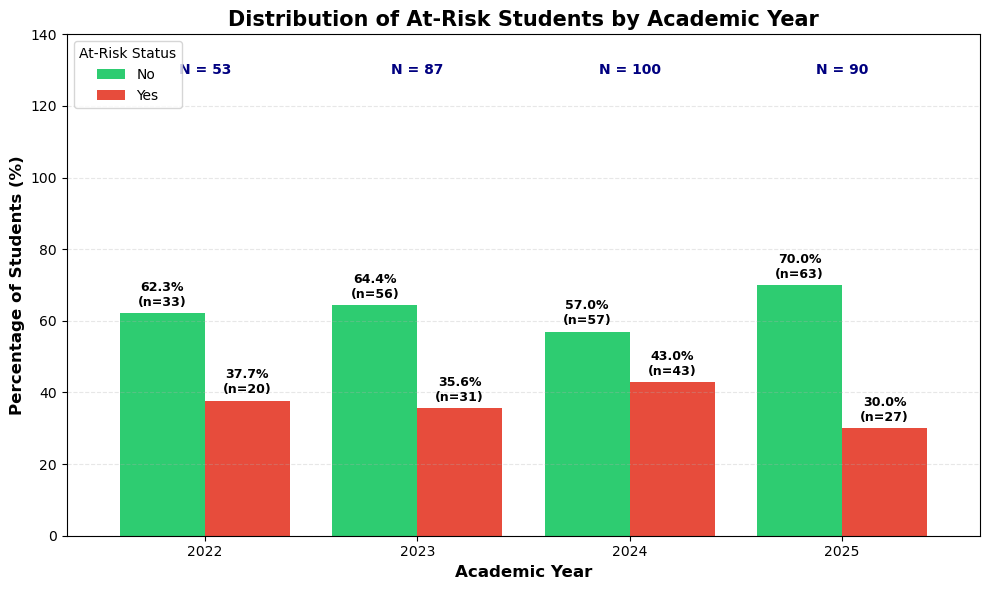

In [33]:
col = df["Academic Year"]   # or whatever the column is named

# Percentage table
academic = (
    pd.crosstab(col, df["At_Risk_Status"], normalize="index") * 100
)
for status in ["No", "Yes"]:
    if status not in academic.columns:
        academic[status] = 0
academic = academic[["No", "Yes"]]

# Actual counts per category
counts = col.value_counts().reindex(academic.index)

ax = academic.plot(kind="bar", figsize=(10, 6), width=0.8,
                   color=["#2ecc71", "#e74c3c"])

# Bar labels: percentage + count
for container, status in zip(ax.containers, ["No", "Yes"]):
    labels = [
        f"{pct:.1f}%\n(n={int(round(pct/100*counts.loc[cat]))})"
        for cat, pct in zip(academic.index, academic[status])
    ]
    ax.bar_label(container, labels=labels, padding=3,
                 fontsize=9, fontweight="bold")

# N labels on a fixed top row — no collision with bar labels
ax.set_ylim(0, 140)
n_y = 130

for i, cat in enumerate(academic.index):
    ax.text(i, n_y, f"N = {int(counts.loc[cat])}",
            ha="center", va="center",
            fontsize=10, fontweight="bold", color="navy")

ax.set_title("Distribution of At-Risk Students by Academic Year",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Academic Year", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage of Students (%)", fontsize=12, fontweight="bold")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="At-Risk Status", loc="upper left")
plt.tight_layout()
plt.show()

In [34]:
year_table = pd.crosstab(df['Academic Year'], df['At_Risk_Status'])
chi_square_report(year_table, "Academic Year vs At-Risk Status")

--- Chi-Square Test: Academic Year vs At-Risk Status ---
Chi² = 3.5159, df = 3, p = 0.3187
Cramér's V = 0.1032
→ No significant association (fail to reject H0)



(np.float64(3.515943256141182),
 np.float64(0.31870021336487236),
 np.float64(0.10322002472126292))

Funding Distribution.

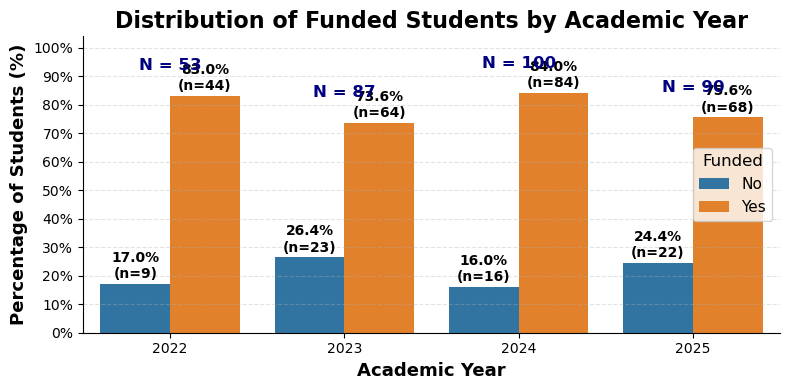

In [35]:
# Plot funding distribution
summary = (
    df.assign(Funded=to_readable(df['Funded'], YESNO_LABELS))
      .groupby(['Academic Year', 'Funded'])
      .size()
      .reset_index(name='Count')
)
summary['Academic Year'] = summary['Academic Year'].astype(str)
summary['Total'] = summary.groupby('Academic Year')['Count'].transform('sum')
summary['Percentage'] = summary['Count'] / summary['Total'] * 100

years = sorted(summary['Academic Year'].unique())
funded_order = sorted(summary['Funded'].unique())

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=summary, x='Academic Year', y='Percentage', hue='Funded', hue_order=funded_order)

for container, category in zip(ax.containers, funded_order):
    data = summary[summary['Funded'] == category].sort_values('Academic Year').reset_index(drop=True)
    for bar, (_, row) in zip(container, data.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f"{row['Percentage']:.1f}%\n(n={int(row['Count'])})",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

for i, year in enumerate(years):
    total = summary.loc[summary['Academic Year'] == year, 'Total'].iloc[0]
    ymax = summary.loc[summary['Academic Year'] == year, 'Percentage'].max()
    ax.text(i, ymax + 8, f"N = {int(total)}", ha='center', va='bottom', fontsize=12, fontweight='bold', color='navy')

ax.set_ylim(0, max(summary['Percentage']) + 20)
ax.set_ylabel("Percentage of Students (%)", fontsize=13, fontweight='bold')
ax.set_xlabel("Academic Year", fontsize=13, fontweight='bold')
ax.set_title("Distribution of Funded Students by Academic Year", fontsize=16, fontweight='bold')
ax.set_yticks(range(0, 101, 10))
ax.set_yticklabels([f"{i}%" for i in range(0, 101, 10)])
ax.legend(title='Funded', fontsize=11, title_fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.35)
sns.despine()
plt.tight_layout()
plt.show()


Gender Distribution

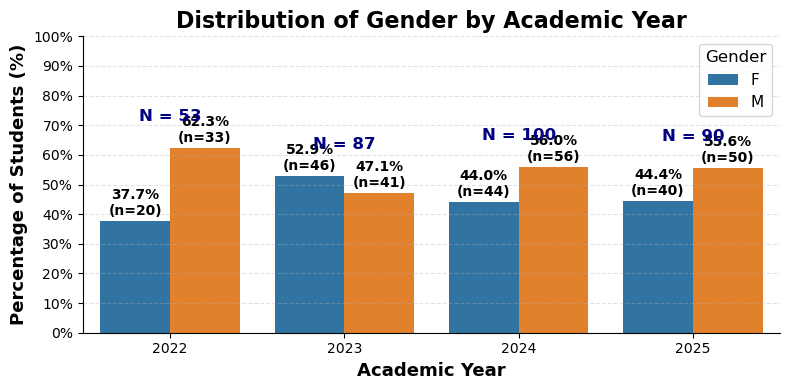

In [36]:
# Plot Gender Distribution
summary = (
    df.assign(Gender=to_readable(df['Gender'], GENDER_LABELS))
      .groupby(['Academic Year', 'Gender'])
      .size()
      .reset_index(name='Count')
)
summary['Academic Year'] = summary['Academic Year'].astype(str)
summary['Total'] = summary.groupby('Academic Year')['Count'].transform('sum')
summary['Percentage'] = summary['Count'] / summary['Total'] * 100

years = sorted(summary['Academic Year'].unique())
gender_order = list(summary['Gender'].drop_duplicates())

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=summary, x='Academic Year', y='Percentage', hue='Gender', hue_order=gender_order)

for container, gender in zip(ax.containers, gender_order):
    data = summary[summary['Gender'] == gender].sort_values('Academic Year').reset_index(drop=True)
    for bar, (_, row) in zip(container, data.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f"{row['Percentage']:.1f}%\n(n={int(row['Count'])})",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

for i, year in enumerate(years):
    total = summary.loc[summary['Academic Year'] == year, 'Total'].iloc[0]
    ymax = summary.loc[summary['Academic Year'] == year, 'Percentage'].max()
    ax.text(i, ymax + 8, f"N = {int(total)}", ha='center', va='bottom', fontsize=12, fontweight='bold', color='navy')

ax.set_ylim(0, max(summary['Percentage']) + 20)
ax.set_ylabel("Percentage of Students (%)", fontsize=13, fontweight='bold')
ax.set_xlabel("Academic Year", fontsize=13, fontweight='bold')
ax.set_title("Distribution of Gender by Academic Year", fontsize=16, fontweight='bold')
ax.set_yticks(range(0, 101, 10))
ax.set_yticklabels([f"{i}%" for i in range(0, 101, 10)])
ax.legend(title='Gender', fontsize=11, title_fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.35)
sns.despine()
plt.tight_layout()
plt.show()


Bursary Type

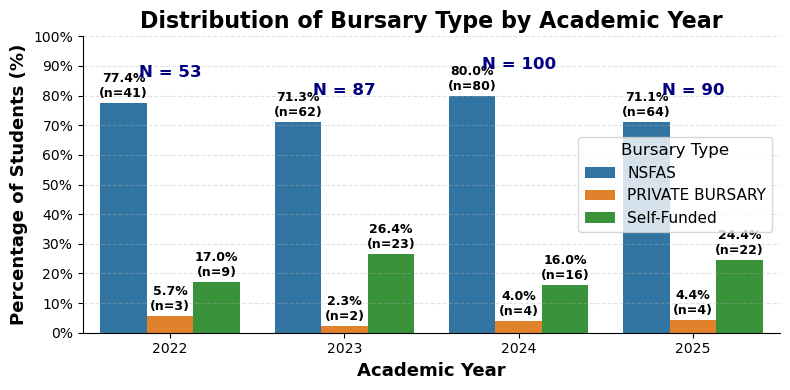

In [37]:
# Bursary Type Distr.
summary = (
    df.groupby(['Academic Year', 'Bursary Type'])
      .size()
      .reset_index(name='Count')
)
summary['Academic Year'] = summary['Academic Year'].astype(str)
summary['Total'] = summary.groupby('Academic Year')['Count'].transform('sum')
summary['Percentage'] = summary['Count'] / summary['Total'] * 100

years = sorted(summary['Academic Year'].unique())
bursary_order = ['NSFAS', 'PRIVATE BURSARY', 'Self-Funded']
bursary_order = [b for b in bursary_order if b in summary['Bursary Type'].unique()]

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=summary, x='Academic Year', y='Percentage', hue='Bursary Type', hue_order=bursary_order)

for container, bursary in zip(ax.containers, bursary_order):
    data = summary[summary['Bursary Type'] == bursary].sort_values('Academic Year').reset_index(drop=True)
    for bar, (_, row) in zip(container, data.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f"{row['Percentage']:.1f}%\n(n={int(row['Count'])})",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, year in enumerate(years):
    total = summary.loc[summary['Academic Year'] == year, 'Total'].iloc[0]
    ymax = summary.loc[summary['Academic Year'] == year, 'Percentage'].max()
    ax.text(i, ymax + 8, f"N = {int(total)}", ha='center', va='bottom', fontsize=12, fontweight='bold', color='navy')

ax.set_ylim(0, max(summary['Percentage']) + 20)
ax.set_ylabel("Percentage of Students (%)", fontsize=13, fontweight='bold')
ax.set_xlabel("Academic Year", fontsize=13, fontweight='bold')
ax.set_title("Distribution of Bursary Type by Academic Year", fontsize=16, fontweight='bold')
ax.set_yticks(range(0, 101, 10))
ax.set_yticklabels([f"{i}%" for i in range(0, 101, 10)])
ax.legend(title='Bursary Type', fontsize=11, title_fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.35)
sns.despine()
plt.tight_layout()
plt.show()


In [38]:
print("Gender values:")
print(df['Gender'].value_counts(dropna=False))

print("\nAt_Risk_Status values:")
print(df['At_Risk_Status'].value_counts(dropna=False))

Gender values:
Gender
M    180
F    150
Name: count, dtype: int64

At_Risk_Status values:
At_Risk_Status
No     209
Yes    121
Name: count, dtype: int64


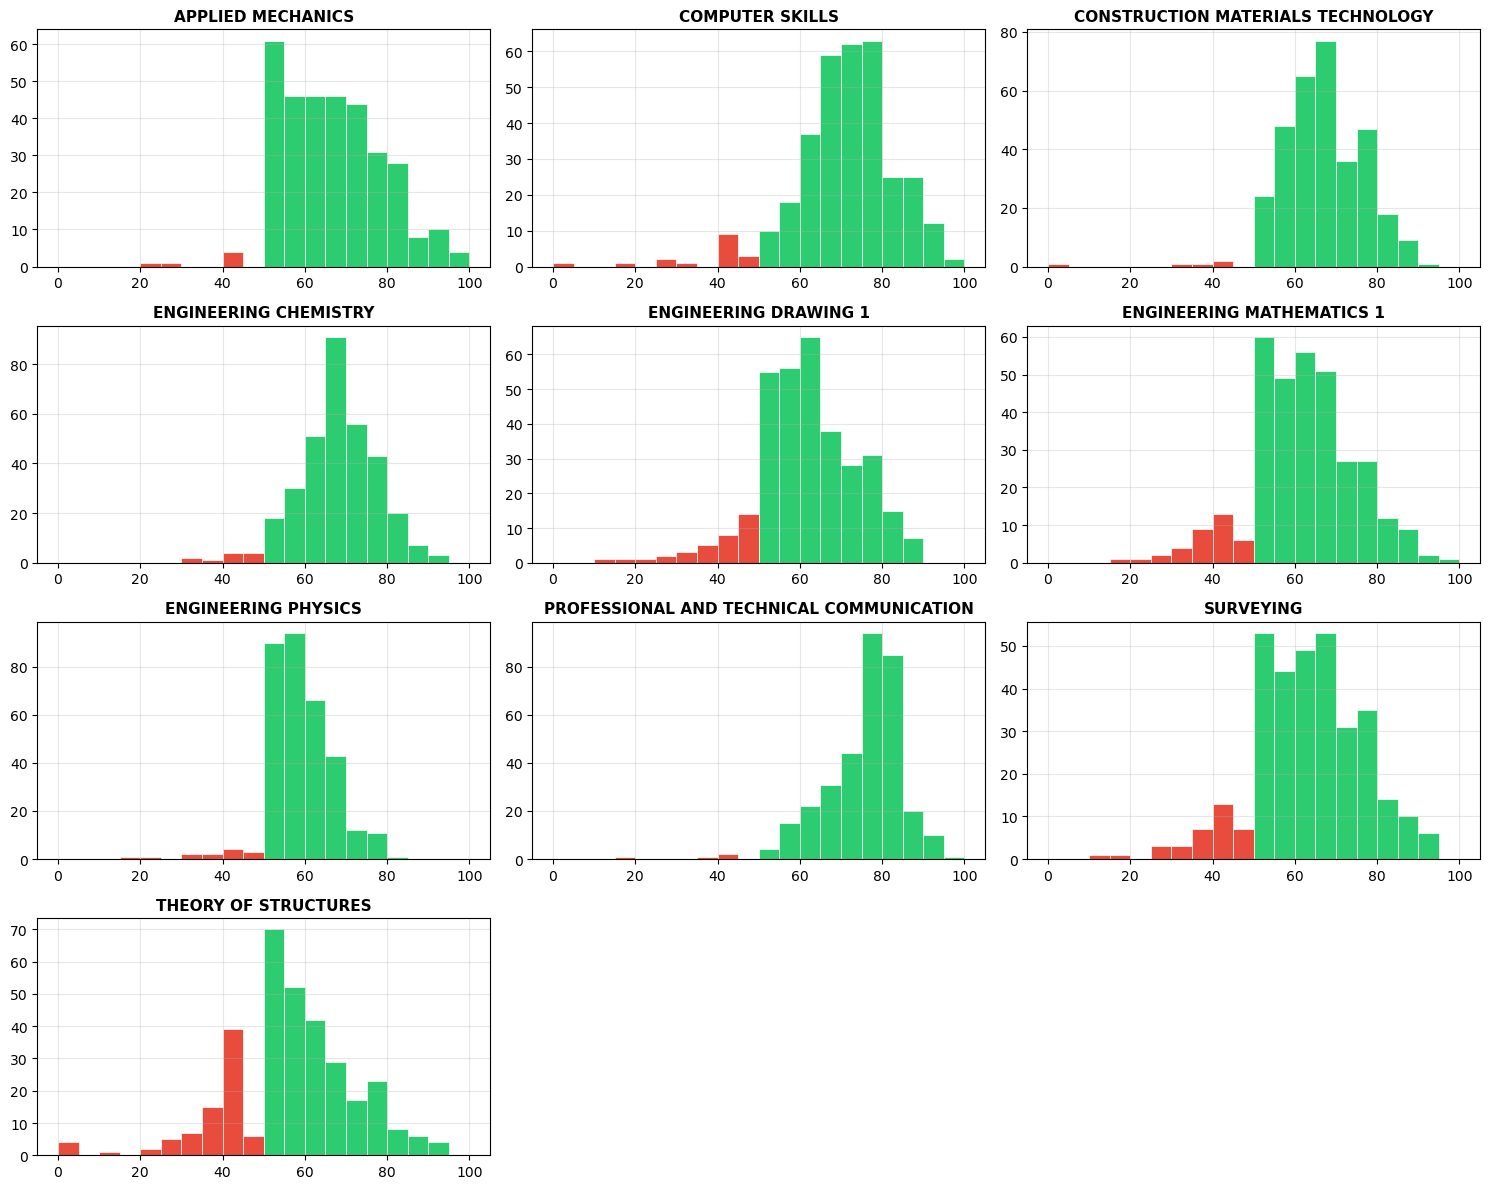

In [39]:
subject_cols = [
    'APPLIED MECHANICS', 'COMPUTER SKILLS', 'CONSTRUCTION MATERIALS TECHNOLOGY',
    'ENGINEERING CHEMISTRY', 'ENGINEERING DRAWING 1', 'ENGINEERING MATHEMATICS 1',
    'ENGINEERING PHYSICS', 'PROFESSIONAL AND TECHNICAL COMMUNICATION', 'SURVEYING',
    'THEORY OF STRUCTURES'
]

# 10 subjects, 3-column grid → 4 rows (last has 1 empty)
n_cols = 3
n_rows = int(np.ceil(len(subject_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 12))
axes = axes.flatten()

RED = '#e74c3c'
GREEN = '#2ecc71'
PASS = 50

for i, col in enumerate(subject_cols):
    ax = axes[i]
    data = df[col].dropna()
    bins = np.arange(0, 105, 5)  # or use hist auto
    n, edges, patches = ax.hist(data, bins=bins, edgecolor='white', linewidth=0.5)
    for patch, left, right in zip(patches, edges[:-1], edges[1:]):
        center = (left + right) / 2
        patch.set_facecolor(GREEN if center >= PASS else RED)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.grid(alpha=0.3)

# hide unused axes
for j in range(len(subject_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

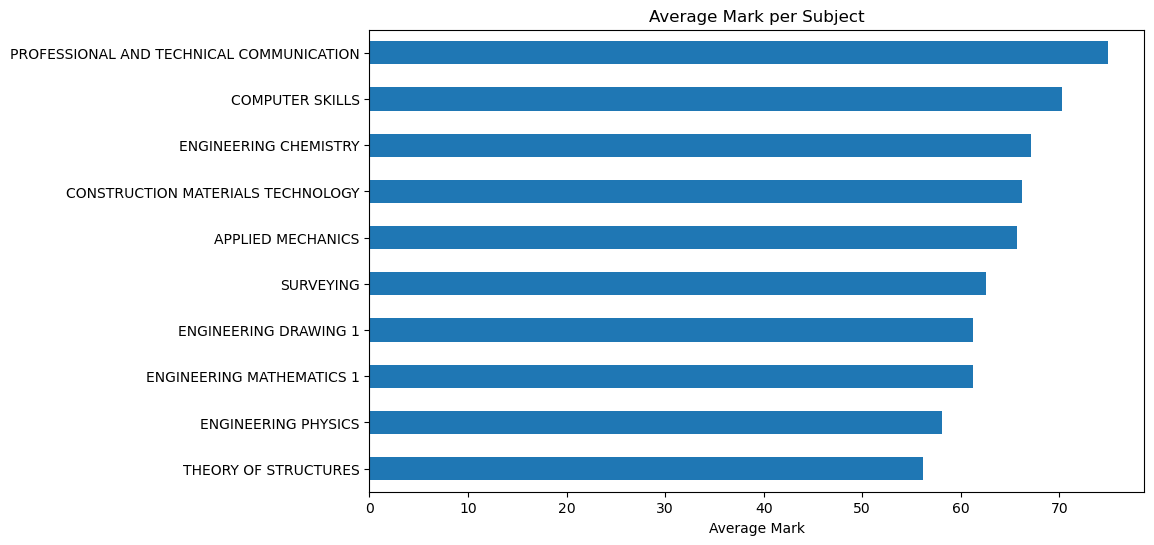

In [40]:
# Average mark per subject (subject_cols defined above)
mean_marks = df[subject_cols].mean().sort_values()

plt.figure(figsize=(10,6))
mean_marks.plot(kind='barh')
plt.title("Average Mark per Subject")
plt.xlabel("Average Mark")
plt.show()


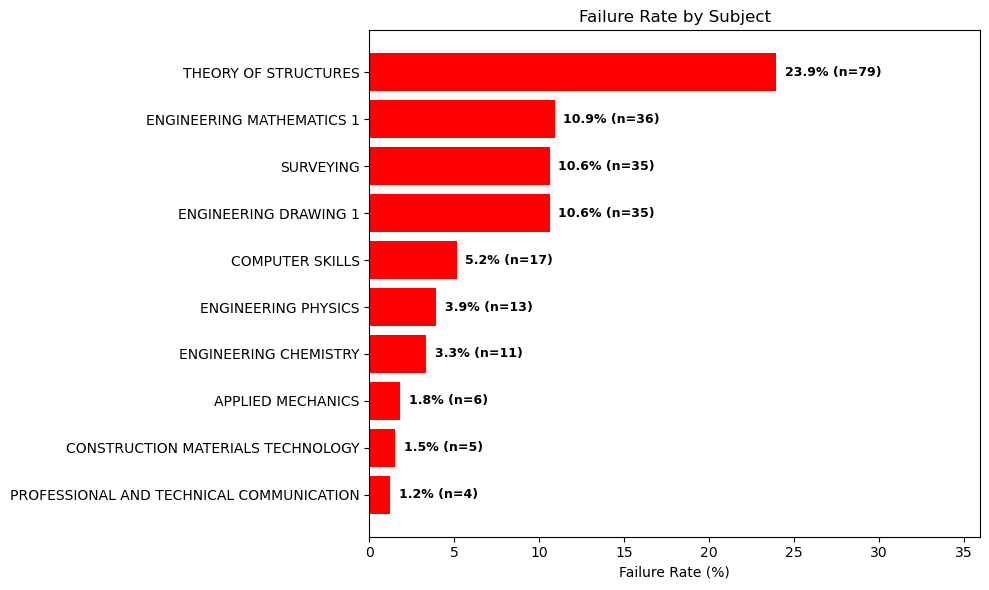

In [41]:
failure_rate = (df[subject_cols] < 50).mean() * 100
failure_counts = (df[subject_cols] < 50).sum()

failure_rate = failure_rate.sort_values()
failure_counts = failure_counts.reindex(failure_rate.index)

plt.figure(figsize=(10, 6))
bars = plt.barh(failure_rate.index, failure_rate.values, color='red')

for bar, rate, count in zip(bars, failure_rate.values, failure_counts.values):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
              f"{rate:.1f}% (n={int(count)})", va='center', fontsize=9, fontweight='bold')

plt.xlabel("Failure Rate (%)")
plt.title("Failure Rate by Subject")
plt.xlim(0, max(failure_rate.values) + 12)
plt.tight_layout()
plt.show()


In [42]:
df['Risk'] = df['At_Risk_Status'].map({'No':0,'Yes':1})

corr = df[subject_cols + ['Age_At_Enrolment','Risk']].corr()

corr['Risk'].sort_values()

df = df.drop(columns=['Risk'])

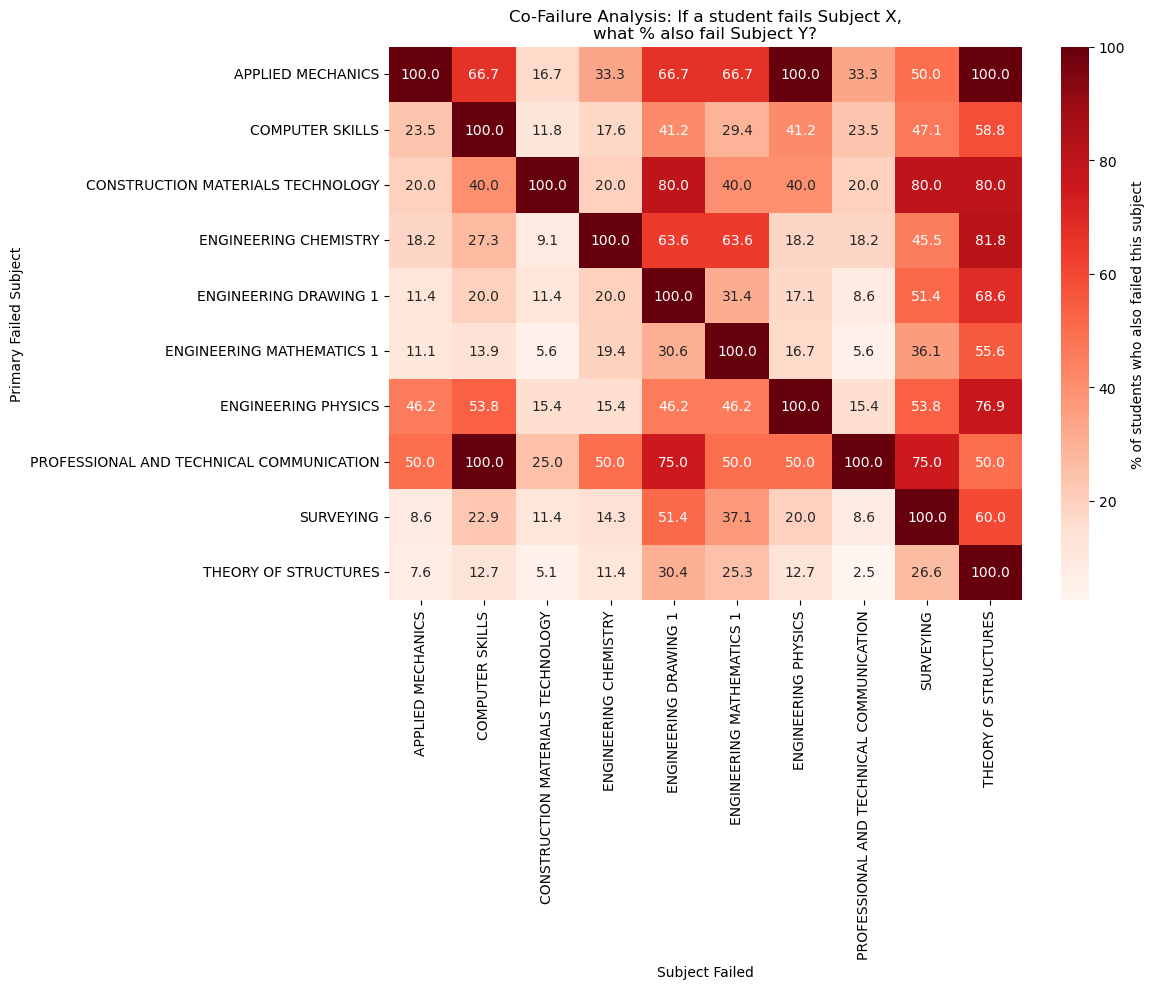

In [43]:
# Create a separate dataframe ONLY for co-failure analysis
df_cofailure = df.copy()

# Create binary failure indicators in the separate dataframe
for col in subject_cols:
    df_cofailure[f"{col}_failed"] = (
        df_cofailure[col] < 50
    ).astype(int)

# Calculate co-failure matrix
co_failure_matrix = pd.DataFrame(
    index=subject_cols,
    columns=subject_cols,
    dtype=float
)

for subj_i in subject_cols:

    failed_i = df_cofailure[
        df_cofailure[f"{subj_i}_failed"] == 1
    ]

    for subj_j in subject_cols:

        if len(failed_i) == 0:
            co_failure_matrix.loc[subj_i, subj_j] = 0
        else:
            co_failure = (
                failed_i[f"{subj_j}_failed"].sum()
                / len(failed_i)
            ) * 100

            co_failure_matrix.loc[subj_i, subj_j] = co_failure


# Plot
plt.figure(figsize=(12, 10))

sns.heatmap(
    co_failure_matrix,
    annot=True,
    cmap="Reds",
    fmt=".1f",
    cbar_kws={
        "label": "% of students who also failed this subject"
    }
)

plt.title(
    "Co-Failure Analysis: If a student fails Subject X,\n"
    "what % also fail Subject Y?"
)

plt.xlabel("Subject Failed")
plt.ylabel("Primary Failed Subject")

plt.tight_layout()
plt.show()

In [44]:
# Make a separate copy so the modelling dataframe is not changed
df_cofailure = df.copy()

# Create failure indicators ONLY in the co-failure dataframe
for col in subject_cols:
    df_cofailure[f"{col}_failed"] = (
        df_cofailure[col] < 50
    ).astype(int)


# Calculate all pairwise co-failure probabilities
results = []

for i, subj_i in enumerate(subject_cols):
    for j, subj_j in enumerate(subject_cols):

        # Skip diagonal (same subject)
        if i != j:

            # Students who failed subject A
            failed_i = df_cofailure[
                df_cofailure[f"{subj_i}_failed"] == 1
            ]

            if len(failed_i) > 0:

                # Number of students who also failed subject B
                count = int(
                    failed_i[f"{subj_j}_failed"].sum()
                )

                # Total students who failed subject A
                total = len(failed_i)

                # Percentage of A-failures who also failed B
                co_failure_pct = (count / total) * 100

                results.append({
                    "Subject_A": subj_i,
                    "Subject_B": subj_j,
                    "A_Failures": total,
                    "Both_Failures": count,
                    "Co_Failure_%": co_failure_pct
                })


# Convert results to DataFrame
co_failure_df = pd.DataFrame(results)

# Sort from strongest to weakest relationship
co_failure_df = co_failure_df.sort_values(
    "Co_Failure_%",
    ascending=False
)


# Display top 10
print("Top 10 Strongest Co-Failure Relationships:")
print(
    co_failure_df.head(10).to_string(index=False)
)

Top 10 Strongest Co-Failure Relationships:
                               Subject_A             Subject_B  A_Failures  Both_Failures  Co_Failure_%
                       APPLIED MECHANICS   ENGINEERING PHYSICS           6              6    100.000000
PROFESSIONAL AND TECHNICAL COMMUNICATION       COMPUTER SKILLS           4              4    100.000000
                       APPLIED MECHANICS  THEORY OF STRUCTURES           6              6    100.000000
                   ENGINEERING CHEMISTRY  THEORY OF STRUCTURES          11              9     81.818182
       CONSTRUCTION MATERIALS TECHNOLOGY             SURVEYING           5              4     80.000000
       CONSTRUCTION MATERIALS TECHNOLOGY ENGINEERING DRAWING 1           5              4     80.000000
       CONSTRUCTION MATERIALS TECHNOLOGY  THEORY OF STRUCTURES           5              4     80.000000
                     ENGINEERING PHYSICS  THEORY OF STRUCTURES          13             10     76.923077
PROFESSIONAL AND TECH

Outlier Detection and Treatment

                                Variable   Q1   Q3  Lower Bound  Upper Bound  Outliers  Outlier %
                        Age_At_Enrolment 19.0 20.0         17.5         21.5        45      13.64
                         COMPUTER SKILLS 65.0 78.0         45.5         97.5        14       4.24
                    THEORY OF STRUCTURES 50.0 65.0         27.5         87.5        14       4.24
                   ENGINEERING CHEMISTRY 62.0 72.0         47.0         87.0        13       3.94
PROFESSIONAL AND TECHNICAL COMMUNICATION 70.0 81.0         53.5         97.5         7       2.12
               ENGINEERING MATHEMATICS 1 53.0 69.0         29.0         93.0         6       1.82
                     ENGINEERING PHYSICS 53.0 63.0         38.0         78.0         6       1.82
                   ENGINEERING DRAWING 1 54.0 69.0         31.5         91.5         5       1.52
       CONSTRUCTION MATERIALS TECHNOLOGY 60.0 72.0         42.0         90.0         4       1.21
                    

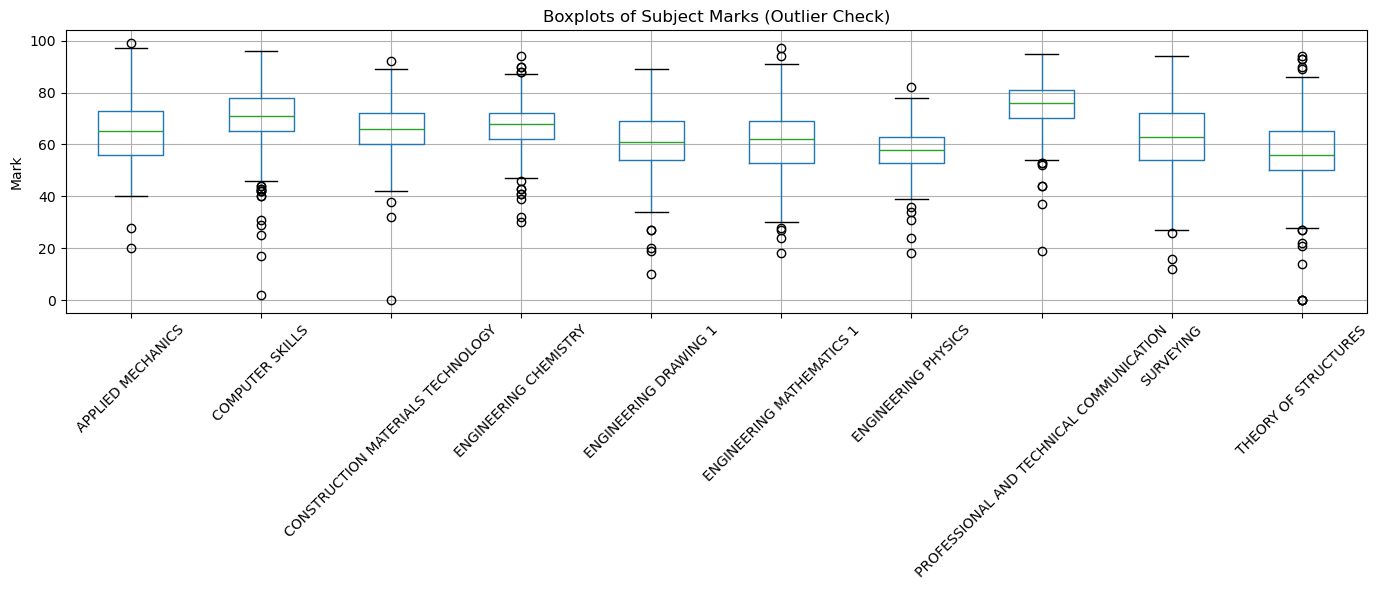

In [45]:
# Outlier Detection and Treatment (Methodology 3.4)
# Identify outliers in the numeric variables using descriptive statistics
# (IQR method), then decide whether to remove, modify, or retain them.

numeric_check_cols = subject_cols + ['Age_At_Enrolment']

outlier_summary = []
for col in numeric_check_cols:
    series = pd.to_numeric(df[col], errors='coerce')
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((series < lower) | (series > upper)).sum()
    outlier_summary.append({
        'Variable': col, 'Q1': round(q1, 2), 'Q3': round(q3, 2),
        'Lower Bound': round(lower, 2), 'Upper Bound': round(upper, 2),
        'Outliers': int(n_outliers),
        'Outlier %': round(n_outliers / series.notna().sum() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values('Outliers', ascending=False)
print(outlier_df.to_string(index=False))

# Visualise
plt.figure(figsize=(14, 6))
df[subject_cols].boxplot(rot=45)
plt.title("Boxplots of Subject Marks (Outlier Check)")
plt.ylabel("Mark")
plt.tight_layout()
plt.show()


In [46]:
# Decision: RETAIN outliers in the subject-mark variables.
# Unlike measurement noise, a very low or very high mark is a genuine,
# meaningful academic outcome (and low marks directly drive the At-Risk
# target variable), so removing or capping them would remove real signal
# and bias the study. Age_At_Enrolment outliers are also retained for the
# same reason (mature/older first-year students are a real subgroup, not
# a data-entry error), consistent with Methodology 3.4.
